# ANALISIS PROVINSI JAWA — Tmax × UTCImax (1996–2025)
## Notebook gabungan hasil penelitian | gaya jurnal | enam provinsi

**Provinsi:** Banten, DKI Jakarta, Jawa Barat, Jawa Tengah, DI Yogyakarta, dan Jawa Timur.

**Adaptasi dari notebook asli pengguna:** `TMAX_UTCI_6PROVINSI_GABUNGAN_JOURNAL_SMOOTH_1996_2025(1).ipynb`. Semua jenis analisis dan keluarga figure dipertahankan: distribusi KDE absolut/relatif, indeks heatwave tahunan, klimatologi provinsi, tren, peta smooth, studi kasus overlap, dan klimatologi bulanan.

**Path utama:** `D:\Daps\Data`. Hasil Tmax diambil dari **cache ber-fingerprint** milik workflow Tmax Jawa; hasil UTCI dari Step 5 Jawa. Hanya menggunakan file output Jawa milikmu. Analisis numerik tetap memakai **native common grid**; interpolasi hanya untuk visualisasi peta.

> **Catatan resolusi:** Pada grid ERA5 yang kasar, DKI Jakarta mungkin tidak berisi pusat grid. Notebook tidak mengarang data DKI: panel tersebut akan ditandai sebagai tidak tercakup dan nilainya `NaN`, sambil tetap memproses lima provinsi lainnya. Untuk analisis DKI yang sahih, diperlukan grid beresolusi memadai.


## 0. Paket dan konfigurasi
Jalankan `pip install numpy pandas xarray netCDF4 matplotlib scipy cartopy shapely openpyxl` pada environment Python VS Code. Cartopy dapat mengunduh berkas peta Natural Earth sekali ketika pertama dijalankan. **Periksa folder konfigurasi** sebelum Run All.

In [1]:
# ============================================================
# 1. IMPORT, PATH OTOMATIS DAN PENGATURAN — JAWA 1996–2025
# ============================================================
from pathlib import Path
import os, json, re, warnings
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.colors as mcolors
import cartopy.crs as ccrs
import cartopy.io.shapereader as shpreader
from scipy.interpolate import griddata, RegularGridInterpolator
from shapely.ops import unary_union
from IPython.display import display
from netCDF4 import Dataset
from scipy.stats import gaussian_kde, theilslopes, kendalltau, pearsonr
warnings.filterwarnings('ignore', category=RuntimeWarning)

# Hanya path Daps. Override bila folder Tmax tidak dapat dideteksi.
DATA_BASE = Path(os.environ.get('DAPS_DATA_BASE', r'D:\Daps\Data'))
TMAX_ROOT_OVERRIDE = None   # contoh: Path(r'D:\Daps\Data\Hasil_Tmax\HEATWAVE_JAWA_JOURNAL_OUTPUT')
TMAX_RAW_DIR_OVERRIDE = None   # folder .nc sumber suhu maksimum
TMAX_COORDS_NPZ = None      # alternatif raw: .npz dengan 'lat' dan 'lon' urutan grid CACHE
TMAX_CACHE_TAG_OVERRIDE = None  # opsi jika banyak fingerprint: 'jawa_1996_2025_xxxxxxxx'
SHAPEFILE_ADMIN1 = None   # alternatif Natural Earth: path .shp lokal (WGS84)

UTCI_ROOT = DATA_BASE / 'UTCI' / 'Hasil_UTCI_Jawa_1996_2025'
UTCI_COMBINED = UTCI_ROOT / 'UTCI_Jawa_Heatwave_Journal_SMOOTH'
UTCI_DATA_DIR = UTCI_COMBINED / 'data'
UTCI_DAILY_FILE = UTCI_ROOT / '03_utci_dailymax_1996_2025_C_Jawa.nc'
UTCI_THRESHOLD_FILE = UTCI_DATA_DIR / 'UTCI_Jawa_Calendar15d_Thresholds_P90_P95_1996_2025.nc'
UTCI_METRICS_FILE = UTCI_DATA_DIR / 'UTCI_Jawa_Heatwave_Metrics_AllScenarios_1996_2025.nc'

OUTPUT_DIR = UTCI_ROOT / 'TMAX_UTCI_6_PROVINSI_JAWA_GABUNGAN_JOURNAL_SMOOTH'
PLOT_DIR = OUTPUT_DIR / 'plots'
TABLE_DIR = OUTPUT_DIR / 'tables'

START_YEAR, END_YEAR = 1996, 2025
PERCENTILE = 90              # 90 atau 95
MIN_DURATION = 3             # 3, 4, 5 hari berturut-turut
MAIN_SCENARIO = f'P{PERCENTILE}_D{MIN_DURATION}'
GRID_TOL = 1e-4              # cocokkan pusat grid, tidak regridding data analitik
KDE_BW_METHOD = 'scott'
MAX_KDE_SAMPLES = 40_000
RANDOM_SEED = 42
FIG_DPI, SAVE_PDF, SHOW_FIGURES = 800, True, True
TMAX_COLOR = '#d95f02'
UTCI_COLOR = '#3b5bdb'
AUTO_CASE = True
CASE_SELECTION = 'overlap'   # overlap | contrast | tmax | utci
CASE_CENTER = '2016-04-15'
CASE_HALF_WINDOW_DAYS, CASE_SMOOTH_DAYS = 10, 3
MAP_EXTENT = [104.5, 116.5, -9.3, -4.9]
DISPLAY_RENDER = 'smooth'   # smooth / native; image only
DISPLAY_NX, DISPLAY_NY = 650, 260
METRIC_CODES = ['HWN', 'HWF', 'HWD', 'HWA', 'HWM']
# Nama cache/NetCDF sumber memakai HWA_abs dan HWM_abs (bukan HWA_absolute/HWM_absolute).
# Pertahankan definisi metrik: absolute = suhu saat episode; excess = selisih di atas ambang.
INTENSITY_MODE = 'absolute'  # absolute / excess
INTENSITY_SUFFIX = 'abs' if INTENSITY_MODE == 'absolute' else 'excess'
METRIC_KEYS = {'HWN':'HWN', 'HWF':'HWF', 'HWD':'HWD',
               'HWA':f'HWA_{INTENSITY_SUFFIX}', 'HWM':f'HWM_{INTENSITY_SUFFIX}'}
METRIC_UNIT = {'HWN':'events/year', 'HWF':'days/year', 'HWD':'days',
               'HWA':'°C excess' if INTENSITY_MODE=='excess' else '°C',
               'HWM':'°C excess' if INTENSITY_MODE=='excess' else '°C'}
if PERCENTILE not in (90,95) or MIN_DURATION not in (3,4,5):
    raise ValueError('Skenario hanya P90/P95 × D3/D4/D5.')
if INTENSITY_MODE not in ('absolute','excess'):
    raise ValueError('INTENSITY_MODE = absolute atau excess.')
if DISPLAY_RENDER not in ('smooth','native'):
    raise ValueError('DISPLAY_RENDER = smooth atau native.')

# --- Temukan Tmax Jawa yang punya metadata serta cache skenario terpilih ---
def cache_is_jawa(root):
    cache = root / 'cache'
    if not cache.is_dir():return False
    for mp in cache.glob('daily_metadata_jawa_1996_2025_*.json'):
        tag=mp.stem.replace('daily_metadata_','',1)
        try:
            meta=json.loads(mp.read_text(encoding='utf-8'))
            if str(meta.get('region','')).strip().lower()!='jawa':continue
            if list(meta.get('period',[])) != [START_YEAR, END_YEAR]:continue
            names=[f'daily_tmax_{tag}.dat',f'daily_dates_{tag}.npy',
                   f'calendar_thresholds_P90_P95_W15_{tag}.npz',
                   f'metrics_{MAIN_SCENARIO}_W15_{tag}.npz']
            if all((cache/name).is_file() for name in names):return True
        except (OSError,ValueError,TypeError):continue
    return False

def find_tmax_output(base):
    if TMAX_ROOT_OVERRIDE is not None:
        p=Path(TMAX_ROOT_OVERRIDE)
        if not cache_is_jawa(p):
            raise FileNotFoundError(f'TMAX_ROOT_OVERRIDE belum benar atau cache tidak lengkap: {p}')
        return p
    roots=[base/'Hasil_Tmax',base/'TMAX',base/'Tmax',base/'T2M Max',base]
    known=('HEATWAVE_JAWA_JOURNAL_OUTPUT','Heatwave_Jawa_Journal_Combined',
           'TMAX_Heatwave_Jawa','Heatwave_Jawa')
    candidates=set(roots)|{r/name for r in roots for name in known}
    if base.is_dir():
        base_depth=len(base.parts)
        for current,subdirs,files in os.walk(base):
            where=Path(current)
            if where.name.lower()=='cache' and any(
                name.startswith('daily_metadata_jawa_1996_2025_') and name.endswith('.json') for name in files):
                candidates.add(where.parent)
            if len(where.parts)-base_depth>=7:subdirs[:]=[]
            else:subdirs[:]=[d for d in subdirs if d.lower() not in
                                {'plots','figures','maps_netcdf','site-packages','.git','__pycache__','1996-2025'}]
    valid=sorted({p.resolve() for p in candidates if cache_is_jawa(p)},key=str)
    if len(valid)==1:return valid[0]
    if len(valid)>1:
        raise RuntimeError('Ada beberapa hasil Tmax Jawa valid. Isi TMAX_ROOT_OVERRIDE:\n - '+'\n - '.join(map(str,valid)))
    raise FileNotFoundError('Cache heatwave Tmax JAWA tidak ditemukan di '+str(base)+
         '\nBuka notebook Tmax Jawa yang sebelumnya berhasil dan salin OUTPUT_DIR '+
         'ke TMAX_ROOT_OVERRIDE. Harus ada cache/daily_metadata_jawa_1996_2025_*.json.')

def contains_nc(folder):return folder.is_dir() and any(folder.glob('*.nc'))
def find_tmax_raw(base,results):
    if TMAX_COORDS_NPZ is not None:
        fp=Path(TMAX_COORDS_NPZ)
        if not fp.is_file():raise FileNotFoundError('Koordinat Tmax npz tidak ditemukan: '+str(fp))
        return None
    if TMAX_RAW_DIR_OVERRIDE is not None:
        fp=Path(TMAX_RAW_DIR_OVERRIDE)
        if not contains_nc(fp):raise FileNotFoundError('Folder NetCDF Tmax kosong: '+str(fp))
        return fp
    qc=results/'QC_input_files.csv'
    if qc.is_file():
        try:
            df=pd.read_csv(qc)
            if 'path' in df:
                dirs={Path(str(v)).parent for v in df['path'].dropna()}
                found=sorted([p for p in dirs if contains_nc(p)],key=str)
                if len(found)==1:return found[0]
        except (OSError,ValueError,TypeError) as exc:print('Info QC path:',exc)
    candidates=[base/'T2M Max',base/'TMax',base/'TMAX'/'1996-2025',base/'Tmax'/'1996-2025',
                base/'TMAX',base/'Tmax',base/'Hasil_Tmax'/'1996-2025']
    found=sorted({p.resolve() for p in candidates if contains_nc(p)},key=str)
    if len(found)==1:return found[0]
    if len(found)>1:raise RuntimeError('Beberapa folder mentah Tmax ditemukan. Isi TMAX_RAW_DIR_OVERRIDE:\n - '+'\n - '.join(map(str,found)))
    raise FileNotFoundError('NetCDF Tmax belum ditemukan. Isi TMAX_RAW_DIR_OVERRIDE = folder TMAX_DIR pada notebook Tmax Jawa.')

TMAX_ROOT=find_tmax_output(DATA_BASE)
TMAX_CACHE=TMAX_ROOT/'cache'
TMAX_RAW_DIR=find_tmax_raw(DATA_BASE,TMAX_ROOT/'results')
for folder in (OUTPUT_DIR,PLOT_DIR,TABLE_DIR):folder.mkdir(parents=True,exist_ok=True)
required=[UTCI_DAILY_FILE,UTCI_THRESHOLD_FILE,UTCI_METRICS_FILE]
missing=[p for p in required if not p.is_file()]
if missing:raise FileNotFoundError('Hasil UTCI Jawa belum tersedia:\n - '+'\n - '.join(map(str,missing)))

mpl.rcParams.update({'font.family':'serif','font.serif':['DejaVu Serif'],'font.size':9,
 'axes.titlesize':10,'axes.labelsize':9,'xtick.labelsize':8,'ytick.labelsize':8,
 'legend.fontsize':8,'figure.titlesize':14,'axes.linewidth':0.8,
 'figure.facecolor':'white','savefig.facecolor':'white'})
print('Wilayah: PULAU JAWA (enam provinsi) | Skenario:',MAIN_SCENARIO)
print('Tmax output:',TMAX_ROOT,'| Tmax NetCDF:',TMAX_RAW_DIR or TMAX_COORDS_NPZ)
print('UTCI output:',UTCI_COMBINED,'| Output perbandingan:',OUTPUT_DIR)


Wilayah: PULAU JAWA (enam provinsi) | Skenario: P90_D3
Tmax output: D:\Daps\Data\TMAX lagi\HEATWAVE_JOURNAL_OUTPUT | Tmax NetCDF: D:\Daps\Data\tm2m max
UTCI output: D:\Daps\Data\UTCI\Hasil_UTCI_Jawa_1996_2025\UTCI_Jawa_Heatwave_Journal_SMOOTH | Output perbandingan: D:\Daps\Data\UTCI\Hasil_UTCI_Jawa_1996_2025\TMAX_UTCI_6_PROVINSI_JAWA_GABUNGAN_JOURNAL_SMOOTH


## 2. Load daily Tmax

Bagian ini mengikuti urutan grid dari notebook TMAX combined:
1. normalisasi longitude,
2. sort longitude,
3. sort latitude,
4. cocokkan dengan daily cache.


In [2]:
# ============================================================
# 2. PILIH SATU FINGERPRINT CACHE TMAX JAWA + KOORDINAT
# ============================================================
cache_groups=[]
for path in sorted(TMAX_CACHE.glob('daily_metadata_jawa_1996_2025_*.json')):
    tag=path.stem.replace('daily_metadata_','',1)
    try:
        meta=json.loads(path.read_text(encoding='utf-8'))
        if str(meta.get('region','')).lower()!='jawa' or list(meta.get('period',[]))!=[START_YEAR,END_YEAR]:continue
        if meta.get('dtype')!='float32':continue
        shape=tuple(int(v) for v in meta['shape'])
        if len(shape)!=3:continue
        fingerprint=tag.split('_')[-1]
        if meta.get('fingerprint')!=fingerprint:continue
        paths={'daily':TMAX_CACHE/f'daily_tmax_{tag}.dat',
               'dates':TMAX_CACHE/f'daily_dates_{tag}.npy',
               'threshold':TMAX_CACHE/f'calendar_thresholds_P90_P95_W15_{tag}.npz',
               'metric':TMAX_CACHE/f'metrics_{MAIN_SCENARIO}_W15_{tag}.npz'}
        if not all(p.is_file() for p in paths.values()):continue
        if paths['daily'].stat().st_size!=int(np.prod(shape))*4:continue
        dates=np.load(paths['dates'],allow_pickle=False).astype('datetime64[D]')
        expected=pd.date_range(f'{START_YEAR}-01-01',f'{END_YEAR}-12-31').to_numpy(dtype='datetime64[D]')
        if not np.array_equal(dates,expected) or len(dates)!=shape[0]:continue
        cache_groups.append((tag,meta,shape,paths,dates))
    except (OSError,ValueError,TypeError,KeyError) as exc:print('Lewati cache:',path.name,exc)
if not cache_groups:raise FileNotFoundError('Cache Tmax Jawa tidak lengkap/invalid pada '+str(TMAX_CACHE))
if TMAX_CACHE_TAG_OVERRIDE:
    cache_groups=[c for c in cache_groups if c[0]==TMAX_CACHE_TAG_OVERRIDE]
    if not cache_groups:raise ValueError('TMAX_CACHE_TAG_OVERRIDE tidak cocok. Periksa fingerprint yang tersedia.')
elif len(cache_groups)>1:
    raise RuntimeError('Ditemukan lebih dari satu cache Tmax Jawa valid; pilih TMAX_CACHE_TAG_OVERRIDE:\n - '+
                       '\n - '.join(c[0] for c in cache_groups))
TMAX_CACHE_TAG,meta,tmax_shape,paths,tmax_dates=cache_groups[0]
TMAX_DAILY_DAT=paths['daily'];TMAX_DAILY_DATES=paths['dates'];TMAX_META=TMAX_CACHE/f'daily_metadata_{TMAX_CACHE_TAG}.json'
TMAX_THRESHOLD_NPZ=paths['threshold'];TMAX_METRIC_CACHE=paths['metric']
tmax_values=np.memmap(TMAX_DAILY_DAT,dtype='float32',mode='r',shape=tmax_shape)

if TMAX_COORDS_NPZ is not None:
    with np.load(Path(TMAX_COORDS_NPZ),allow_pickle=False) as z:
        tmax_lat=np.asarray(z['lat'],dtype=float)
        tmax_lon=np.asarray(z['lon'],dtype=float)
else:
    raw_files=sorted(TMAX_RAW_DIR.glob('*.nc'))
    if not raw_files:raise FileNotFoundError('Tidak ada *.nc untuk koordinat Tmax: '+str(TMAX_RAW_DIR))
    with Dataset(raw_files[0],'r') as nc:
        names={k.lower():k for k in nc.variables}
        def read_coord(options):
            for key in options:
                if key.lower() in names:return np.asarray(nc.variables[names[key.lower()]][:],dtype=float)
            raise KeyError('Koordinat '+str(options)+' tidak ada pada '+str(raw_files[0]))
        tmax_lat=read_coord(('latitude','lat'))
        tmax_lon=read_coord(('longitude','lon'))
if tmax_lat.ndim!=1 or tmax_lon.ndim!=1:
    raise ValueError('Koordinat Tmax harus satu dimensi.')
if np.nanmax(tmax_lon)>180:tmax_lon=((tmax_lon+180)%360)-180
# Notebook Tmax Jawa menyimpan cache berdasarkan lat/lon ascending
# TMAX_COORDS_NPZ jika digunakan juga harus disimpan dari koordinat cache yang sesuai.
tmax_lat=np.sort(tmax_lat)
tmax_lon=np.sort(tmax_lon)
if (len(tmax_lat),len(tmax_lon))!=tmax_shape[1:]:
    raise ValueError('Koordinat Tmax tidak sama dengan dimensi cache: '+str(tmax_shape))
if np.any(np.diff(tmax_lat)<=0) or np.any(np.diff(tmax_lon)<=0):
    raise ValueError('Koordinat Tmax tidak unik.')
print('Fingerprint:',TMAX_CACHE_TAG,'| Shape:',tmax_shape,'| Tanggal:',len(tmax_dates))
print('Batas Tmax (lon,lat):',tmax_lon[[0,-1]],tmax_lat[[0,-1]])


Fingerprint: jawa_1996_2025_12a9a5da2da0 | Shape: (10958, 15, 45) | Tanggal: 10958
Batas Tmax (lon,lat): [104. 115.] [-9.  -5.5]


## 3. Load UTCImax dan alignment common grid

Tmax disubset mengikuti koordinat UTCI **tanpa interpolasi**. Setelah itu hanya grid yang valid pada kedua dataset yang dipakai untuk perbandingan distribusi.


In [3]:
# ============================================================
# 3. LOAD UTCI + ALIGN TMAX TO UTCI GRID
# ============================================================

utci_ds = xr.open_dataset(
    UTCI_DAILY_FILE,
    engine="netcdf4",
    decode_times=True,
    decode_timedelta=False,
)

if "utci_max" not in utci_ds.data_vars:
    raise ValueError(
        "Variabel utci_max tidak ditemukan."
    )

utci_da = utci_ds[
    "utci_max"
].transpose(
    "time",
    "latitude",
    "longitude"
)

utci_values = np.asarray(
    utci_da.values,
    dtype=np.float32,
)

utci_dates = (
    pd.DatetimeIndex(
        utci_da["time"].values
    )
    .to_numpy(
        dtype="datetime64[D]"
    )
)

utci_lat = np.asarray(
    utci_ds["latitude"].values,
    dtype=float,
)

utci_lon = np.asarray(
    utci_ds["longitude"].values,
    dtype=float,
)


if not np.array_equal(
    tmax_dates,
    utci_dates
):
    raise ValueError(
        "Tanggal Tmax dan UTCI tidak identik."
    )


def find_coord_indices(
    source_coord,
    target_coord,
    tol=1e-4,
    label="coord",
):

    source_coord = np.asarray(
        source_coord,
        dtype=float,
    )

    target_coord = np.asarray(
        target_coord,
        dtype=float,
    )

    idx = []
    misses = []

    for value in target_coord:

        hits = np.where(
            np.isclose(
                source_coord,
                value,
                atol=tol,
                rtol=0,
            )
        )[0]

        if len(hits) == 1:
            idx.append(
                int(hits[0])
            )
        else:
            misses.append(
                (
                    float(value),
                    len(hits),
                )
            )

    if misses:
        raise ValueError(
            f"Tidak semua {label} UTCI cocok unik dengan grid Tmax. "
            f"Contoh gagal: {misses[:8]}"
        )

    return np.asarray(
        idx,
        dtype=int,
    )


tmax_lat_idx = find_coord_indices(
    tmax_lat,
    utci_lat,
    GRID_TOL,
    "latitude",
)

tmax_lon_idx = find_coord_indices(
    tmax_lon,
    utci_lon,
    GRID_TOL,
    "longitude",
)


tmax_values_cmp = np.take(
    np.take(
        tmax_values,
        tmax_lat_idx,
        axis=1,
    ),
    tmax_lon_idx,
    axis=2,
).astype(
    np.float32,
    copy=False,
)


utci_values_cmp = utci_values

cmp_lat = utci_lat.copy()
cmp_lon = utci_lon.copy()


if tmax_values_cmp.shape != utci_values_cmp.shape:
    raise RuntimeError(
        "Shape Tmax dan UTCI masih berbeda setelah alignment."
    )


tmax_valid_grid = np.any(
    np.isfinite(
        tmax_values_cmp
    ),
    axis=0,
)

utci_valid_grid = np.any(
    np.isfinite(
        utci_values_cmp
    ),
    axis=0,
)

common_grid = (
    tmax_valid_grid
    &
    utci_valid_grid
)


print(
    "Tmax aligned :",
    tmax_values_cmp.shape
)

print(
    "UTCI         :",
    utci_values_cmp.shape
)

print(
    "Tmax valid   :",
    int(
        tmax_valid_grid.sum()
    )
)

print(
    "UTCI valid   :",
    int(
        utci_valid_grid.sum()
    )
)

print(
    "Common grid  :",
    int(
        common_grid.sum()
    )
)


Tmax aligned : (10958, 12, 36)
UTCI         : (10958, 12, 36)
Tmax valid   : 176
UTCI valid   : 176
Common grid  : 176


## 4. Load P90/P95 threshold dan bentuk daily threshold

Threshold Tmax dan UTCI memakai kalender 365 hari. Untuk 29 Februari digunakan rata-rata threshold 28 Februari dan 1 Maret.


In [4]:
# ============================================================
# 4. LOAD + ALIGN DAILY THRESHOLDS
# ============================================================

# -----------------------------
# TMAX THRESHOLD
# -----------------------------
zt = np.load(
    TMAX_THRESHOLD_NPZ
)

tmax_thr_cal_raw = np.asarray(
    zt[
        f"P{PERCENTILE}"
    ],
    dtype=np.float32,
)

tmax_thr_cal = np.take(
    np.take(
        tmax_thr_cal_raw,
        tmax_lat_idx,
        axis=1,
    ),
    tmax_lon_idx,
    axis=2,
).astype(
    np.float32,
    copy=False,
)


# -----------------------------
# UTCI THRESHOLD
# -----------------------------
utci_thr_ds = xr.open_dataset(
    UTCI_THRESHOLD_FILE,
    engine="netcdf4",
    decode_timedelta=False,
)

utci_thr_cal = np.asarray(
    utci_thr_ds[
        f"P{PERCENTILE}"
    ].values,
    dtype=np.float32,
)


# QC mutlak: threshold UTCI harus berada di koordinat dan urutan grid yang sama
if 'latitude' in utci_thr_ds.coords and 'longitude' in utci_thr_ds.coords:
    if not (np.allclose(utci_thr_ds['latitude'].values, cmp_lat, atol=GRID_TOL, rtol=0)
            and np.allclose(utci_thr_ds['longitude'].values, cmp_lon, atol=GRID_TOL, rtol=0)):
        raise ValueError('Koordinat threshold UTCI berbeda dari daily UTCI; alignment tidak aman.')
if utci_thr_cal.shape[0] != 365 or tmax_thr_cal.shape[0] != 365:
    raise ValueError('Threshold harus memiliki 365 calendar-day slices.')

if tmax_thr_cal.shape != utci_thr_cal.shape:
    raise ValueError(
        f"Threshold shape berbeda: "
        f"Tmax={tmax_thr_cal.shape}, "
        f"UTCI={utci_thr_cal.shape}"
    )


# -----------------------------
# 365-DAY INDEX
# -----------------------------
all_dates = pd.DatetimeIndex(
    tmax_dates.astype(
        "datetime64[ns]"
    )
)


def noleap_day_index(
    dti
):

    out = np.full(
        len(dti),
        -1,
        dtype=np.int16,
    )

    for i, ts in enumerate(
        dti
    ):

        if (
            ts.month == 2
            and ts.day == 29
        ):
            continue

        doy = (
            ts.dayofyear - 1
        )

        if (
            ts.is_leap_year
            and ts.month > 2
        ):
            doy -= 1

        out[i] = doy

    return out


day_index = noleap_day_index(
    all_dates
)


def calendar_to_daily(
    cal
):

    out = np.full(
        (
            len(day_index),
            cal.shape[1],
            cal.shape[2],
        ),
        np.nan,
        dtype=np.float32,
    )

    regular = (
        day_index >= 0
    )

    out[
        regular
    ] = cal[
        day_index[
            regular
        ]
    ]

    feb29 = (
        day_index < 0
    )

    if np.any(
        feb29
    ):

        out[
            feb29
        ] = (
            0.5
            *
            (
                cal[58]
                +
                cal[59]
            )
        )

    return out


tmax_thr_daily = calendar_to_daily(
    tmax_thr_cal
)

utci_thr_daily = calendar_to_daily(
    utci_thr_cal
)


print(
    "Tmax threshold daily:",
    tmax_thr_daily.shape
)

print(
    "UTCI threshold daily:",
    utci_thr_daily.shape
)


Tmax threshold daily: (10958, 12, 36)
UTCI threshold daily: (10958, 12, 36)


## 5. Buat mask enam provinsi Jawa

Mask dibuat dari Natural Earth Admin-1 lalu dipotong lagi dengan **common grid**.


In [5]:
# ============================================================
# 5. MASK ENAM PROVINSI JAWA PADA GRID BERSAMA
# ============================================================
import unicodedata
province_order=['Banten','DKI Jakarta','Jawa Barat','Jawa Tengah','DI Yogyakarta','Jawa Timur']
province_short={'Banten':'Banten','DKI Jakarta':'DKI','Jawa Barat':'Jabar',
                'Jawa Tengah':'Jateng','DI Yogyakarta':'DIY','Jawa Timur':'Jatim'}
province_aliases={
    'Banten':('banten',),
    'DKI Jakarta':('jakarta raya','jakarta','dki jakarta','daerah khusus ibukota jakarta'),
    'Jawa Barat':('jawa barat','west java'),
    'Jawa Tengah':('jawa tengah','central java'),
    'DI Yogyakarta':('yogyakarta','di yogyakarta','daerah istimewa yogyakarta','special region of yogyakarta'),
    'Jawa Timur':('jawa timur','east java'),
}
def norm_name(x):
    x=unicodedata.normalize('NFKD',str(x)).encode('ascii','ignore').decode('ascii').lower().strip()
    return ' '.join(x.replace('_',' ').replace('-',' ').split())
try:
    from shapely import contains_xy
    def geom_contains(geom, x, y):return contains_xy(geom.buffer(1e-8),x,y)
except ImportError:
    from shapely.vectorized import contains
    def geom_contains(geom, x, y):return contains(geom.buffer(1e-8),x,y)

if SHAPEFILE_ADMIN1 is None:
    admin1_file=shpreader.natural_earth(resolution='10m',category='cultural',name='admin_1_states_provinces')
else:
    admin1_file=str(SHAPEFILE_ADMIN1)
    if not Path(admin1_file).is_file():raise FileNotFoundError('Shapefile admin-1 tidak ditemukan: '+admin1_file)
province_geometries={p:[] for p in province_order}
for record in shpreader.Reader(admin1_file).records():
    att=record.attributes
    country=' '.join(norm_name(att.get(k,'')) for k in ('admin','geonunit','name_en','name'))
    if SHAPEFILE_ADMIN1 is None and 'indonesia' not in country:
        # Pada Natural Earth admin1 field 'admin' / 'geonunit' memuat Indonesia.
        continue
    names=[norm_name(att.get(k,'')) for k in ('name','name_en','name_local','name_alt','woe_name')]
    for prov,aliases in province_aliases.items():
        if any(name == norm_name(alias) for name in names for alias in aliases):
            province_geometries[prov].append(record.geometry)
            break
lon2d,lat2d=np.meshgrid(cmp_lon,cmp_lat)
province_masks={}
for prov in province_order:
    geoms=province_geometries[prov]
    if not geoms:raise RuntimeError('Batas '+prov+' tidak ditemukan di admin-1: '+str(admin1_file)+
                                     '. Periksa nama kolom shapefile atau pakai Natural Earth.')
    mask=np.zeros(common_grid.shape,dtype=bool)
    for geom in geoms:mask |= np.asarray(geom_contains(geom,lon2d,lat2d),dtype=bool)
    province_masks[prov]=mask & common_grid
    print(f'{prov:19s}: {int(province_masks[prov].sum()):3d} grid asli')
print('Grid 0 untuk provinsi kecil (khususnya DKI) akan dilaporkan sebagai NO DATA, bukan diisi buatan.')


def annotate_grid_coverage(ax,province):
    if not province_masks[province].any():
        ax.text(.5,.52,'NO NATIVE ERA5 GRID\nProvince not represented',
                ha='center',va='center',transform=ax.transAxes,
                fontsize=9,color='#a13c36',fontweight='bold',
                bbox=dict(facecolor='white',edgecolor='#cba7a0',alpha=.93))


Banten             :  10 grid asli
DKI Jakarta        :   1 grid asli
Jawa Barat         :  50 grid asli
Jawa Tengah        :  47 grid asli
DI Yogyakarta      :   3 grid asli
Jawa Timur         :  65 grid asli
Grid 0 untuk provinsi kecil (khususnya DKI) akan dilaporkan sebagai NO DATA, bukan diisi buatan.


## 6. Ekstrak distribusi per provinsi

Observasi Tmax dan UTCImax dipertahankan hanya ketika **keduanya valid pada tanggal dan grid yang sama**. Ini membuat perbandingan KDE lebih adil.

Untuk `Figure 2`, exceedance dihitung terhadap threshold lokal-harian masing-masing indeks.


In [6]:
# ============================================================
# 6. EXTRACT COMMON-SUPPORT DISTRIBUTIONS
# ============================================================

def deterministic_subsample(
    values,
    max_samples,
    seed,
):

    values = np.asarray(
        values,
        dtype=float,
    )

    values = values[
        np.isfinite(
            values
        )
    ]

    if len(values) <= max_samples:
        return values

    rng = np.random.default_rng(
        seed
    )

    idx = rng.choice(
        len(values),
        size=max_samples,
        replace=False,
    )

    return values[
        idx
    ]


province_data = {}
summary_rows = []


for ip, province in enumerate(
    province_order
):

    region = province_masks[
        province
    ]

    # time × selected grid
    T = np.asarray(
        tmax_values_cmp[
            :,
            region
        ],
        dtype=np.float32,
    )

    U = np.asarray(
        utci_values_cmp[
            :,
            region
        ],
        dtype=np.float32,
    )

    TT = np.asarray(
        tmax_thr_daily[
            :,
            region
        ],
        dtype=np.float32,
    )

    UT = np.asarray(
        utci_thr_daily[
            :,
            region
        ],
        dtype=np.float32,
    )

    # Wajib valid pada kedua indeks + kedua threshold
    obs_valid = (
        np.isfinite(T)
        &
        np.isfinite(U)
        &
        np.isfinite(TT)
        &
        np.isfinite(UT)
    )

    T_abs = T[
        obs_valid
    ].astype(
        float
    )

    U_abs = U[
        obs_valid
    ].astype(
        float
    )

    T_thr = TT[
        obs_valid
    ].astype(
        float
    )

    U_thr = UT[
        obs_valid
    ].astype(
        float
    )

    T_exc = (
        T_abs
        -
        T_thr
    )

    U_exc = (
        U_abs
        -
        U_thr
    )

    province_data[
        province
    ] = {
        "T_abs": T_abs,
        "U_abs": U_abs,
        "T_thr": T_thr,
        "U_thr": U_thr,
        "T_exc": T_exc,
        "U_exc": U_exc,
        "T_abs_kde": deterministic_subsample(
            T_abs,
            MAX_KDE_SAMPLES,
            RANDOM_SEED + ip * 10 + 1,
        ),
        "U_abs_kde": deterministic_subsample(
            U_abs,
            MAX_KDE_SAMPLES,
            RANDOM_SEED + ip * 10 + 2,
        ),
        "T_exc_kde": deterministic_subsample(
            T_exc,
            MAX_KDE_SAMPLES,
            RANDOM_SEED + ip * 10 + 3,
        ),
        "U_exc_kde": deterministic_subsample(
            U_exc,
            MAX_KDE_SAMPLES,
            RANDOM_SEED + ip * 10 + 4,
        ),
    }

    T_positive = (
        T_exc[
            T_exc > 0
        ]
    )

    U_positive = (
        U_exc[
            U_exc > 0
        ]
    )

    summary_rows.append({
        "province": province,
        "common_grid_cells": int(
            region.sum()
        ),
        "common_observations": int(
            len(T_abs)
        ),
        "tmax_mean_C": float(
            np.nanmean(
                T_abs
            )
        ),
        "utci_mean_C": float(
            np.nanmean(
                U_abs
            )
        ),
        "tmax_std_C": float(
            np.nanstd(
                T_abs
            )
        ),
        "utci_std_C": float(
            np.nanstd(
                U_abs
            )
        ),
        f"tmax_mean_P{PERCENTILE}_C": float(
            np.nanmean(
                T_thr
            )
        ),
        f"utci_mean_P{PERCENTILE}_C": float(
            np.nanmean(
                U_thr
            )
        ),
        f"tmax_raw_above_P{PERCENTILE}_pct": float(
            100.0
            *
            np.mean(
                T_exc > 0
            )
        ),
        f"utci_raw_above_P{PERCENTILE}_pct": float(
            100.0
            *
            np.mean(
                U_exc > 0
            )
        ),
        "tmax_mean_positive_excess_C": (
            float(
                np.mean(
                    T_positive
                )
            )
            if len(T_positive)
            else np.nan
        ),
        "utci_mean_positive_excess_C": (
            float(
                np.mean(
                    U_positive
                )
            )
            if len(U_positive)
            else np.nan
        ),
    })


summary_df = pd.DataFrame(
    summary_rows
)

display(
    summary_df
)

summary_csv = (
    TABLE_DIR
    /
    f"Provincial_Tmax_UTCI_Distribution_QC_P{PERCENTILE}.csv"
)

summary_df.to_csv(
    summary_csv,
    index=False,
)

print(
    "Saved:",
    summary_csv
)


,province,common_grid_cells,common_observations,tmax_mean_C,utci_mean_C,tmax_std_C,utci_std_C,tmax_mean_P90_C,utci_mean_P90_C,tmax_raw_above_P90_pct,utci_raw_above_P90_pct,tmax_mean_positive_excess_C,utci_mean_positive_excess_C
0,Banten,10,109580,29.532311,34.290797,1.567852,3.080928,30.820761,36.593333,9.924256,9.958022,0.414118,0.556649
1,DKI Jakarta,1,10958,30.907786,37.121895,1.398625,1.918809,32.282860,38.912811,9.864939,9.947071,0.422177,0.533058
2,Jawa Barat,50,547900,28.741326,33.853897,2.344655,2.688197,30.179673,35.643450,9.939405,9.922614,0.474470,0.508558
3,Jawa Tengah,47,515026,29.460048,34.978944,2.120898,2.633728,30.834711,36.851662,9.939304,9.937362,0.470472,0.511017
4,DI Yogyakarta,3,32874,29.679884,34.488271,1.438162,2.317244,31.287527,36.923626,9.937945,9.913610,0.578873,0.700132
5,Jawa Timur,65,712270,29.188312,34.086266,2.231464,2.978701,30.525285,36.055640,9.902425,9.912252,0.473454,0.573269


Saved: D:\Daps\Data\UTCI\Hasil_UTCI_Jawa_1996_2025\TMAX_UTCI_6_PROVINSI_JAWA_GABUNGAN_JOURNAL_SMOOTH\tables\Provincial_Tmax_UTCI_Distribution_QC_P90.csv


## 7. Helper KDE

KDE hanya dipakai untuk visualisasi. Statistik QC tidak memakai hasil KDE.


In [7]:
# ============================================================
# 7. KDE HELPER
# ============================================================

def kde_curve(
    values,
    x_grid,
    bw_method=KDE_BW_METHOD,
):

    values = np.asarray(
        values,
        dtype=float,
    )

    values = values[
        np.isfinite(
            values
        )
    ]

    if len(values) < 5:
        return np.full(
            len(x_grid),
            np.nan,
        )

    if np.nanstd(
        values
    ) == 0:

        return np.zeros(
            len(x_grid),
            dtype=float,
        )

    try:
        kde = gaussian_kde(values, bw_method=bw_method)
        return kde(x_grid)
    except (np.linalg.LinAlgError, ValueError):
        return np.full(len(x_grid), np.nan)


# Global absolute range agar semua provinsi punya sumbu X sama
abs_pool = np.concatenate([
    province_data[p]["T_abs_kde"]
    for p in province_order
] + [
    province_data[p]["U_abs_kde"]
    for p in province_order
])

abs_xmin = float(
    np.nanpercentile(
        abs_pool,
        0.2
    )
)

abs_xmax = float(
    np.nanpercentile(
        abs_pool,
        99.8
    )
)

abs_pad = (
    0.04
    *
    (
        abs_xmax
        -
        abs_xmin
    )
)

abs_xgrid = np.linspace(
    abs_xmin - abs_pad,
    abs_xmax + abs_pad,
    500,
)


# Relative/exceedance range dibuat simetris terhadap nol
exc_pool = np.concatenate([
    province_data[p]["T_exc_kde"]
    for p in province_order
] + [
    province_data[p]["U_exc_kde"]
    for p in province_order
])

exc_absmax = float(
    np.nanpercentile(
        np.abs(
            exc_pool
        ),
        99.5
    )
)

if (
    not np.isfinite(
        exc_absmax
    )
    or exc_absmax == 0
):
    exc_absmax = 1.0

exc_xgrid = np.linspace(
    -exc_absmax,
    exc_absmax,
    500,
)

print(
    "Absolute x-range :",
    round(
        abs_xgrid.min(),
        2
    ),
    "to",
    round(
        abs_xgrid.max(),
        2
    ),
    "°C"
)

print(
    "Exceedance range :",
    round(
        exc_xgrid.min(),
        2
    ),
    "to",
    round(
        exc_xgrid.max(),
        2
    ),
    "°C"
)


Absolute x-range : 23.07 to 41.0 °C
Exceedance range : -7.84 to 7.84 °C


# Figure 1 — Absolute daily Tmax vs UTCImax distributions

Garis vertikal berwarna menunjukkan **mean calendar-day threshold** pada provinsi tersebut.

Perlu diingat: Tmax dan UTCImax sama-sama dinyatakan dalam °C, tetapi **makna fisiknya berbeda**. Figure ini digunakan untuk membandingkan bentuk distribusi, bukan menyatakan bahwa UTCI adalah suhu udara.


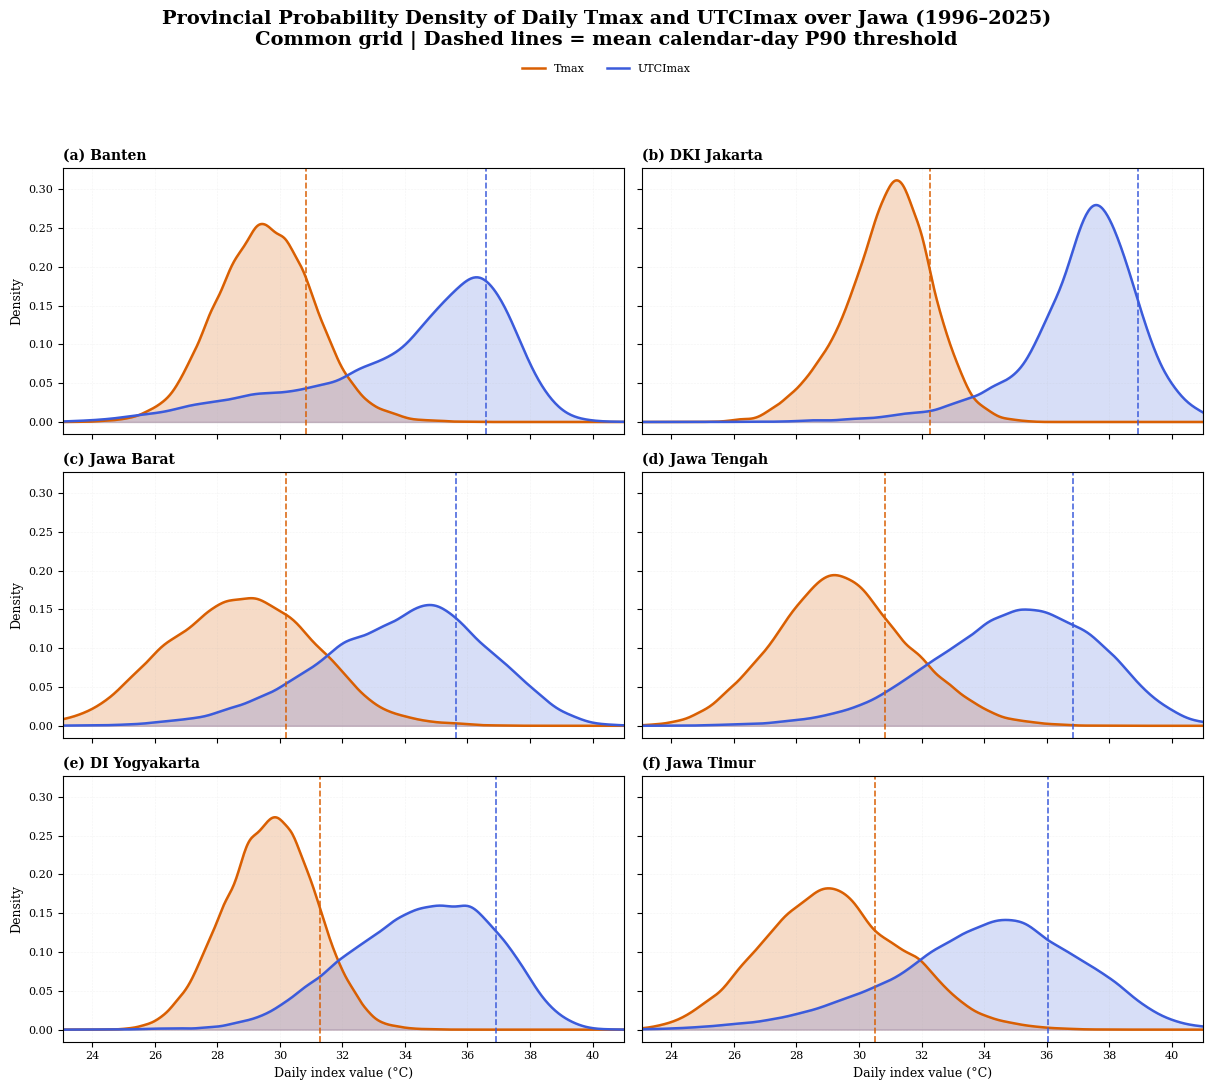

Saved: D:\Daps\Data\UTCI\Hasil_UTCI_Jawa_1996_2025\TMAX_UTCI_6_PROVINSI_JAWA_GABUNGAN_JOURNAL_SMOOTH\plots\FIG01_Provincial_KDE_Absolute_Tmax_UTCImax_P90.png


In [8]:
# ============================================================
# FIGURE 1 — ABSOLUTE KDE BY PROVINCE
# ============================================================

fig, axes = plt.subplots(
    3,
    2,
    figsize=(
        12.2,
        11.0
    ),
    sharex=True,
    sharey=True,
)

panel_letters = [
    "a",
    "b",
    "c",
    "d",
    "e",
    "f",
]


for i, (
    ax,
    province
) in enumerate(
    zip(
        axes.flat,
        province_order
    )
):

    d = province_data[
        province
    ]

    y_t = kde_curve(
        d[
            "T_abs_kde"
        ],
        abs_xgrid,
    )

    y_u = kde_curve(
        d[
            "U_abs_kde"
        ],
        abs_xgrid,
    )


    # Tmax
    ax.plot(
        abs_xgrid,
        y_t,
        color=TMAX_COLOR,
        linewidth=1.8,
        label="Tmax",
    )

    ax.fill_between(
        abs_xgrid,
        0,
        y_t,
        color=TMAX_COLOR,
        alpha=0.22,
    )


    # UTCImax
    ax.plot(
        abs_xgrid,
        y_u,
        color=UTCI_COLOR,
        linewidth=1.8,
        label="UTCImax",
    )

    ax.fill_between(
        abs_xgrid,
        0,
        y_u,
        color=UTCI_COLOR,
        alpha=0.20,
    )


    # Mean calendar-day percentile threshold
    t_thr_mean = float(
        np.nanmean(
            d[
                "T_thr"
            ]
        )
    )

    u_thr_mean = float(
        np.nanmean(
            d[
                "U_thr"
            ]
        )
    )


    ax.axvline(
        t_thr_mean,
        color=TMAX_COLOR,
        linestyle="--",
        linewidth=1.15,
        alpha=0.95,
    )

    ax.axvline(
        u_thr_mean,
        color=UTCI_COLOR,
        linestyle="--",
        linewidth=1.15,
        alpha=0.95,
    )


    ax.set_title(
        f"({panel_letters[i]}) {province}",
        fontweight="bold",
        loc="left",
    )

    ax.grid(
        True,
        linestyle=":",
        linewidth=0.4,
        alpha=0.28,
    )

    ax.set_xlim(
        abs_xgrid.min(),
        abs_xgrid.max(),
    )


# Axis labels
for ax in axes[:, 0]:
    ax.set_ylabel(
        "Density"
    )

for ax in axes[-1, :]:
    ax.set_xlabel(
        "Daily index value (°C)"
    )


# Legend sekali saja
handles, labels = axes[0, 0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    ncol=2,
    frameon=False,
    bbox_to_anchor=(
        0.5,
        0.945
    ),
)

fig.suptitle(
    f"Provincial Probability Density of Daily Tmax and UTCImax over Jawa ({START_YEAR}–{END_YEAR})\n"
    f"Common grid | Dashed lines = mean calendar-day P{PERCENTILE} threshold",
    fontweight="bold",
    y=0.985,
)

for ax,province in zip(axes.flat,province_order):
    annotate_grid_coverage(ax,province)

fig.tight_layout(
    rect=[
        0,
        0,
        1,
        0.92
    ]
)


abs_png = (
    PLOT_DIR
    /
    f"FIG01_Provincial_KDE_Absolute_Tmax_UTCImax_P{PERCENTILE}.png"
)

fig.savefig(
    abs_png,
    dpi=FIG_DPI,
    bbox_inches="tight",
    facecolor="white",
)

if SAVE_PDF:
    fig.savefig(
        abs_png.with_suffix(
            ".pdf"
        ), dpi=FIG_DPI,
        bbox_inches="tight",
        facecolor="white",
    )

plt.show()
plt.close(
    fig
)

print(
    "Saved:",
    abs_png
)


# Figure 2 — Distribution relative to P90/P95 threshold

Ini adalah figure yang lebih adil untuk perbandingan heatwave karena masing-masing indeks dibandingkan dengan threshold lokal-hariannya sendiri:

\[
X - P_x
\]

- `x < 0` = di bawah threshold
- `x = 0` = tepat threshold
- `x > 0` = melebihi threshold

Angka kecil di panel menunjukkan persentase observasi harian yang berada di atas threshold sebelum syarat durasi heatwave diterapkan.


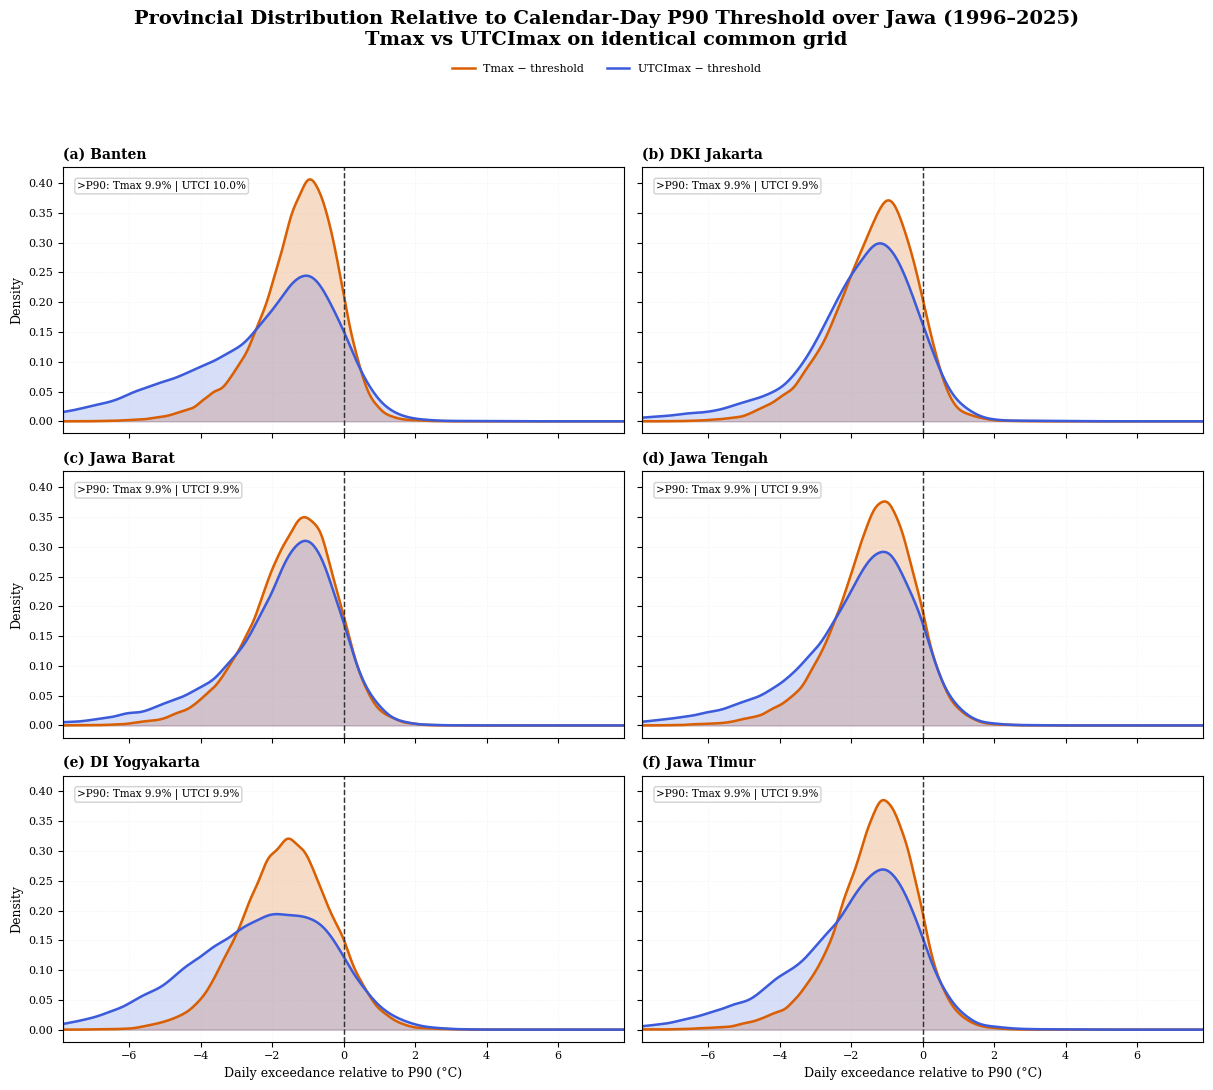

Saved: D:\Daps\Data\UTCI\Hasil_UTCI_Jawa_1996_2025\TMAX_UTCI_6_PROVINSI_JAWA_GABUNGAN_JOURNAL_SMOOTH\plots\FIG02_Provincial_KDE_ThresholdRelative_Tmax_UTCImax_P90.png


In [9]:
# ============================================================
# FIGURE 2 — THRESHOLD-RELATIVE KDE BY PROVINCE
# ============================================================

fig, axes = plt.subplots(
    3,
    2,
    figsize=(
        12.2,
        11.0
    ),
    sharex=True,
    sharey=True,
)


for i, (
    ax,
    province
) in enumerate(
    zip(
        axes.flat,
        province_order
    )
):

    d = province_data[
        province
    ]

    y_t = kde_curve(
        d[
            "T_exc_kde"
        ],
        exc_xgrid,
    )

    y_u = kde_curve(
        d[
            "U_exc_kde"
        ],
        exc_xgrid,
    )


    ax.plot(
        exc_xgrid,
        y_t,
        color=TMAX_COLOR,
        linewidth=1.8,
        label="Tmax − threshold",
    )

    ax.fill_between(
        exc_xgrid,
        0,
        y_t,
        color=TMAX_COLOR,
        alpha=0.22,
    )


    ax.plot(
        exc_xgrid,
        y_u,
        color=UTCI_COLOR,
        linewidth=1.8,
        label="UTCImax − threshold",
    )

    ax.fill_between(
        exc_xgrid,
        0,
        y_u,
        color=UTCI_COLOR,
        alpha=0.20,
    )


    # Threshold boundary
    ax.axvline(
        0,
        color="0.20",
        linestyle="--",
        linewidth=1.05,
    )


    t_pct = (
        100.0
        *
        np.mean(
            d[
                "T_exc"
            ]
            > 0
        )
    )

    u_pct = (
        100.0
        *
        np.mean(
            d[
                "U_exc"
            ]
            > 0
        )
    )


    ax.text(
        0.025,
        0.95,
        (
            f">P{PERCENTILE}: "
            f"Tmax {t_pct:.1f}% | "
            f"UTCI {u_pct:.1f}%"
        ),
        transform=ax.transAxes,
        ha="left",
        va="top",
        fontsize=7.5,
        bbox=dict(
            boxstyle="round,pad=0.22",
            facecolor="white",
            edgecolor="0.80",
            alpha=0.88,
        ),
    )


    ax.set_title(
        f"({panel_letters[i]}) {province}",
        fontweight="bold",
        loc="left",
    )

    ax.grid(
        True,
        linestyle=":",
        linewidth=0.4,
        alpha=0.28,
    )

    ax.set_xlim(
        exc_xgrid.min(),
        exc_xgrid.max(),
    )


for ax in axes[:, 0]:
    ax.set_ylabel(
        "Density"
    )

for ax in axes[-1, :]:
    ax.set_xlabel(
        f"Daily exceedance relative to P{PERCENTILE} (°C)"
    )


handles, labels = (
    axes[0, 0]
    .get_legend_handles_labels()
)

fig.legend(
    handles,
    labels,
    loc="upper center",
    ncol=2,
    frameon=False,
    bbox_to_anchor=(
        0.5,
        0.945
    ),
)


fig.suptitle(
    f"Provincial Distribution Relative to Calendar-Day P{PERCENTILE} Threshold over Jawa ({START_YEAR}–{END_YEAR})\n"
    f"Tmax vs UTCImax on identical common grid",
    fontweight="bold",
    y=0.985,
)


for ax,province in zip(axes.flat,province_order):
    annotate_grid_coverage(ax,province)

fig.tight_layout(
    rect=[
        0,
        0,
        1,
        0.92
    ]
)


exc_png = (
    PLOT_DIR
    /
    f"FIG02_Provincial_KDE_ThresholdRelative_Tmax_UTCImax_P{PERCENTILE}.png"
)

fig.savefig(
    exc_png,
    dpi=FIG_DPI,
    bbox_inches="tight",
    facecolor="white",
)

if SAVE_PDF:
    fig.savefig(
        exc_png.with_suffix(
            ".pdf"
        ), dpi=FIG_DPI,
        bbox_inches="tight",
        facecolor="white",
    )


plt.show()
plt.close(
    fig
)

print(
    "Saved:",
    exc_png
)


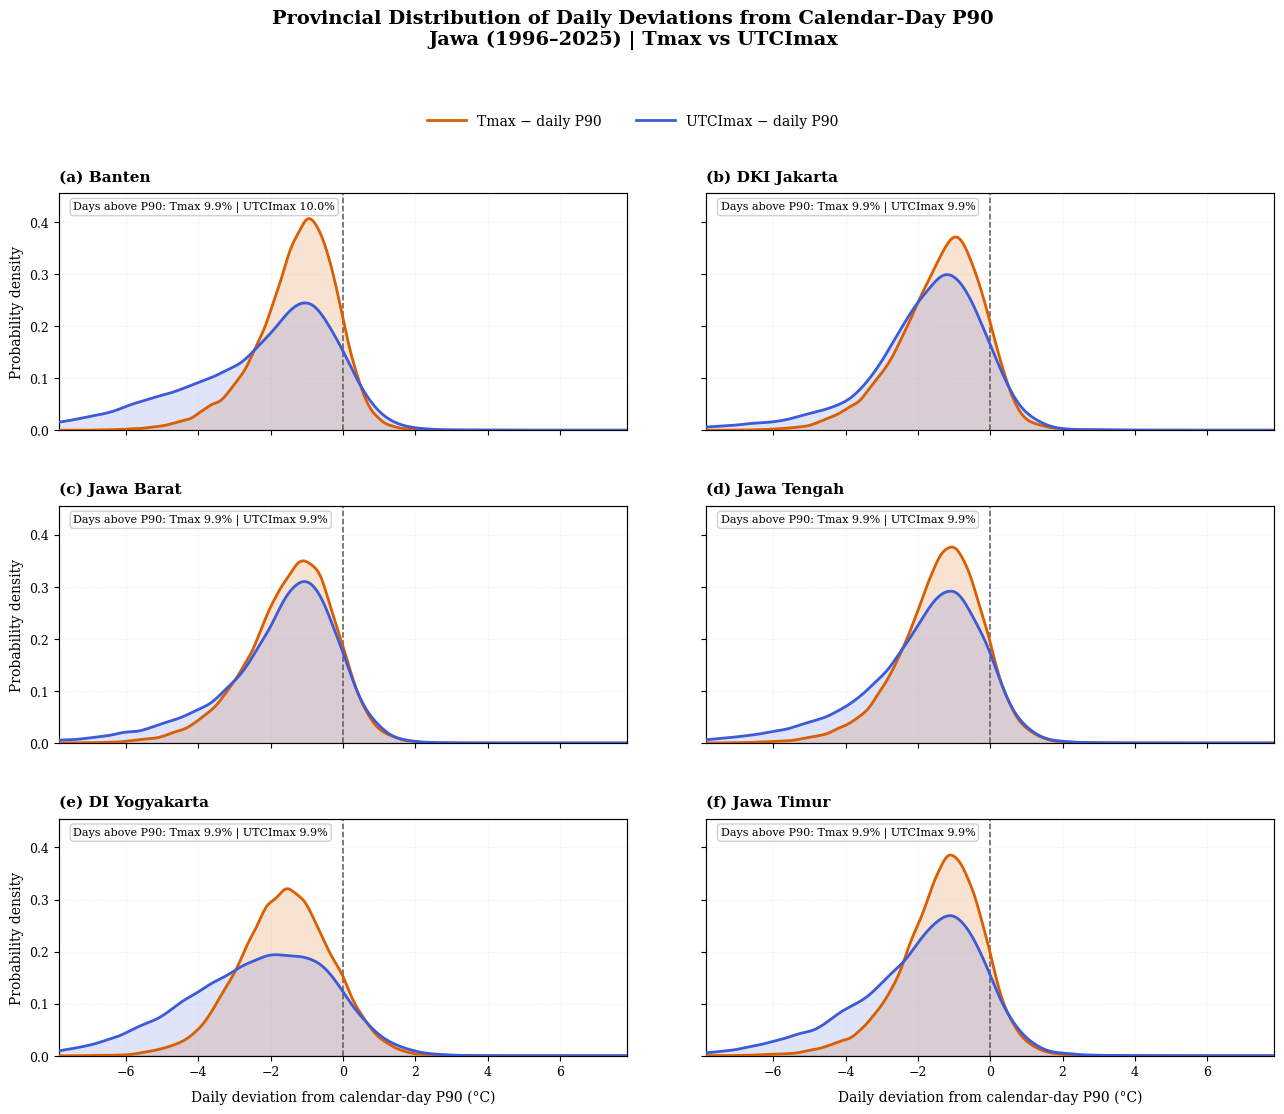

Figure saved: D:\Daps\Data\UTCI\Hasil_UTCI_Jawa_1996_2025\TMAX_UTCI_6_PROVINSI_JAWA_GABUNGAN_JOURNAL_SMOOTH\plots\FIG02B_Provincial_KDE_ThresholdRelative_FixedY_Tmax_UTCImax_P90.png


In [10]:
# ============================================================
# FIGURE 2 — PROVINCIAL DAILY DEVIATION KDE (FIXED Y-LIMIT)
# ============================================================

fig, axes = plt.subplots(
    3, 2,
    figsize=(13.5, 11.5),
    sharex=True,
    sharey=True
)

fig.subplots_adjust(
    left=0.075,
    right=0.975,
    bottom=0.075,
    top=0.825,
    hspace=0.32,
    wspace=0.14
)

# ------------------------------------------------------------
# PRECOMPUTE KDE + GLOBAL Y MAX
# ------------------------------------------------------------
kde_store = {}
global_ymax = 0.0

for province in province_order:
    d = province_data[province]

    y_t = kde_curve(
        d["T_exc_kde"],
        exc_xgrid
    )
    y_u = kde_curve(
        d["U_exc_kde"],
        exc_xgrid
    )

    kde_store[province] = {
        "y_t": y_t,
        "y_u": y_u,
        "T_exc": np.asarray(d["T_exc"]),
        "U_exc": np.asarray(d["U_exc"]),
    }

    finite_y=np.concatenate([y_t[np.isfinite(y_t)],y_u[np.isfinite(y_u)]])
    local_max=float(finite_y.max()) if finite_y.size else 0.0
    if local_max > global_ymax:
        global_ymax = local_max

# kasih ruang di atas biar gak mentok
global_ymax = max(global_ymax * 1.12, 0.01)

# ------------------------------------------------------------
# PLOT
# ------------------------------------------------------------
for i, (ax, province) in enumerate(zip(axes.flat, province_order)):

    y_t = kde_store[province]["y_t"]
    y_u = kde_store[province]["y_u"]
    t_values = kde_store[province]["T_exc"]
    u_values = kde_store[province]["U_exc"]

    # Tmax
    ax.plot(
        exc_xgrid,
        y_t,
        color=TMAX_COLOR,
        linewidth=2.0,
        label=f"Tmax − daily P{PERCENTILE}",
        zorder=3
    )
    ax.fill_between(
        exc_xgrid,
        0,
        y_t,
        color=TMAX_COLOR,
        alpha=0.18
    )

    # UTCImax
    ax.plot(
        exc_xgrid,
        y_u,
        color=UTCI_COLOR,
        linewidth=2.0,
        label=f"UTCImax − daily P{PERCENTILE}",
        zorder=3
    )
    ax.fill_between(
        exc_xgrid,
        0,
        y_u,
        color=UTCI_COLOR,
        alpha=0.16
    )

    # garis ambang
    ax.axvline(
        x=0,
        color="0.35",
        linestyle="--",
        linewidth=1.1,
        zorder=2
    )

    # % hari di atas ambang harian P90
    t_valid = t_values[np.isfinite(t_values)]
    u_valid = u_values[np.isfinite(u_values)]

    t_pct = 100 * np.mean(t_valid > 0) if t_valid.size > 0 else np.nan
    u_pct = 100 * np.mean(u_valid > 0) if u_valid.size > 0 else np.nan

    ax.text(
        0.025,
        0.965,
        (
            f"Days above P{PERCENTILE}: "
            f"Tmax {t_pct:.1f}% | UTCImax {u_pct:.1f}%"
        ),
        transform=ax.transAxes,
        ha="left",
        va="top",
        fontsize=8.0,
        bbox=dict(
            boxstyle="round,pad=0.28",
            facecolor="white",
            edgecolor="0.80",
            alpha=0.92
        ),
        zorder=5
    )

    ax.set_title(
        f"({panel_letters[i]}) {province}",
        loc="left",
        fontsize=11,
        fontweight="bold",
        pad=9
    )

    ax.grid(
        True,
        linestyle=":",
        linewidth=0.55,
        alpha=0.28,
        zorder=0
    )

    ax.set_xlim(exc_xgrid.min(), exc_xgrid.max())
    ax.set_ylim(0, global_ymax)

    ax.tick_params(
        axis="both",
        labelsize=9
    )

    for spine in ax.spines.values():
        spine.set_linewidth(0.85)

# ------------------------------------------------------------
# LABEL AXIS
# ------------------------------------------------------------
for ax in axes[:, 0]:
    ax.set_ylabel(
        "Probability density",
        fontsize=10
    )

for ax in axes[-1, :]:
    ax.set_xlabel(
        f"Daily deviation from calendar-day P{PERCENTILE} (°C)",
        fontsize=10,
        labelpad=8
    )

# ------------------------------------------------------------
# JUDUL & LEGENDA
# ------------------------------------------------------------
fig.suptitle(
    "Provincial Distribution of Daily Deviations from Calendar-Day "
    f"P{PERCENTILE}\n"
    f"Jawa ({START_YEAR}–{END_YEAR}) | Tmax vs UTCImax",
    fontsize=14,
    fontweight="bold",
    y=0.985
)

handles, labels = axes[0, 0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.905),
    ncol=2,
    frameon=False,
    fontsize=10,
    handlelength=2.8,
    columnspacing=2.5
)

# ------------------------------------------------------------
# SAVE
# ------------------------------------------------------------
exc_png = (
    PLOT_DIR /
    f"FIG02B_Provincial_KDE_ThresholdRelative_FixedY_Tmax_UTCImax_P{PERCENTILE}.png"
)

for ax,province in zip(axes.flat,province_order):
    annotate_grid_coverage(ax,province)

fig.savefig(
    exc_png,
    dpi=FIG_DPI,
    bbox_inches="tight",
    facecolor="white"
)

if SAVE_PDF:
    fig.savefig(
        exc_png.with_suffix(".pdf"), dpi=FIG_DPI,
        bbox_inches="tight",
        facecolor="white"
    )

plt.show()
plt.close(fig)

print("Figure saved:", exc_png)


## QC wajib sebelum membuat interpretasi
Sumber KDE memang membandingkan tanggal dan grid yang sama. Grafik indeks tahunan di bawah menggunakan **metriks tahunan dari masing-masing pipeline sumber**, diseleksi ke **grid pusat bersama yang masuk ke enam provinsi**. Ketika validitas data harian antarindikator berbeda, hasilnya perlu ditafsirkan hati-hati. Sel berikut mencetak jumlah grid dan persentase kelengkapan. Jangan lanjut jika koordinat, grid, atau kelengkapan tidak masuk akal.

In [11]:
# ============================================================
# QC CAKUPAN GRID / TANGGAL PER PROVINSI — AMAN UNTUK DKI 0 GRID
# ============================================================
mask_stack=np.stack([province_masks[p] for p in province_order],axis=0)
if np.any(mask_stack.sum(axis=0)>1):
    raise ValueError('Pusat grid milik beberapa provinsi; periksa geometri admin-1.')
province_union_mask=mask_stack.any(axis=0)
if not np.any(province_union_mask):raise ValueError('Mask enam provinsi kosong. Periksa wilayah dan koordinat.')
qc_rows=[]
for p in province_order:
    m=province_masks[p]
    count=int(m.sum())
    if count == 0:
        print('CATATAN CAKUPAN:',p,'tidak punya titik grid ERA5 di pusat polygon. Panel provinsi ini = NaN.')
        qc_rows.append(dict(province=p,common_grid_count=0,tmax_valid_pct=np.nan,
                            utci_valid_pct=np.nan,paired_valid_pct=np.nan))
        continue
    n_total=len(tmax_dates)*count
    tv=np.isfinite(tmax_values_cmp[:,m]); uv=np.isfinite(utci_values_cmp[:,m])
    qc_rows.append(dict(province=p,common_grid_count=count,
        tmax_valid_pct=100*tv.sum()/n_total,utci_valid_pct=100*uv.sum()/n_total,
        paired_valid_pct=100*(tv&uv).sum()/n_total))
coverage_df=pd.DataFrame(qc_rows)
display(coverage_df.round(2))
coverage_df.to_csv(TABLE_DIR/'TABLE00_Coverage_By_Province.csv',index=False)
if (coverage_df.paired_valid_pct.dropna()<90).any():
    print('PERINGATAN: Sebagian provinsi memiliki cakupan paired valid di bawah 90%.')
assert len(tmax_dates)==len(utci_dates)
assert tmax_thr_cal.shape[0]==365 and utci_thr_cal.shape[0]==365


,province,common_grid_count,tmax_valid_pct,utci_valid_pct,paired_valid_pct
0,Banten,10,100.0,100.0,100.0
1,DKI Jakarta,1,100.0,100.0,100.0
2,Jawa Barat,50,100.0,100.0,100.0
3,Jawa Tengah,47,100.0,100.0,100.0
4,DI Yogyakarta,3,100.0,100.0,100.0
5,Jawa Timur,65,100.0,100.0,100.0


## 3. Baca hasil tahunan dari notebook Tmax dan UTCI (P90-D3 / P95-D3)
**Tidak mengulang deteksi heatwave dengan algoritme baru.** Notebook gabungan ini mengambil keluaran **HWN, HWF, HWD, HWA_abs, HWM_abs** dari workflow sumber yang sudah berjalan, agar hasilnya konsisten. Untuk setiap provinsi, rerata antar-grid ditimbang dengan kosinus lintang. Intensitas HWA/HWM yang `NaN` karena tidak ada episode **tidak diganti nol**.

**Perbaikan nama cache:** mode `absolute` dipetakan ke `HWA_abs`/`HWM_abs`, sementara mode `excess` dipetakan ke `HWA_excess`/`HWM_excess`. Tidak ada konversi numerik antar-mode.


In [12]:
# Load metric yearly cache; coordinate Tmax sorted ascending and subset to UTCI native grid.
tcache = np.load(TMAX_METRIC_CACHE)
udy = xr.open_dataset(UTCI_METRICS_FILE, engine='netcdf4', decode_timedelta=False)
if 'year' not in udy.dims:
    raise ValueError('Variabel year tidak tersedia di metrics UTCI.')
if (PERCENTILE not in udy['percentile'].values or
        MIN_DURATION not in udy['min_duration'].values):
    raise ValueError(f'Skenario {MAIN_SCENARIO} tidak tersedia dalam UTCI metrics.')
YEARS = np.arange(START_YEAR, END_YEAR + 1, dtype=int)
if 'years' in tcache and not np.array_equal(tcache['years'], YEARS):
    raise ValueError('Tahun dalam metrics Tmax berbeda dengan 1996–2025.')
if not np.array_equal(udy['year'].values, YEARS):
    raise ValueError('Tahun dalam metrics UTCI berbeda dengan 1996–2025.')
# Pastikan koordinat UTCI annual dan daily benar-benar identik
if not (np.allclose(udy['latitude'].values, cmp_lat, atol=GRID_TOL, rtol=0)
        and np.allclose(udy['longitude'].values, cmp_lon, atol=GRID_TOL, rtol=0)):
    raise ValueError('Grid UTCI annual vs daily tidak cocok; jangan lanjut.')

# QC nama variabel, agar error memberi tahu file sumber dan daftar nama aktual.
expected_metric_keys = list(METRIC_KEYS.values())
missing_tmax = [key for key in expected_metric_keys if key not in tcache.files]
missing_utci = [key for key in expected_metric_keys if key not in udy.data_vars]
if missing_tmax or missing_utci:
    raise KeyError(
        'Nama metrik pada berkas sumber tidak cocok.\n'
        f'  Hilang di cache Tmax ({TMAX_METRIC_CACHE}): {missing_tmax}\n'
        f'  Kunci cache Tmax: {list(tcache.files)}\n'
        f'  Hilang di NetCDF UTCI ({UTCI_METRICS_FILE}): {missing_utci}\n'
        f'  Variabel NetCDF UTCI: {list(udy.data_vars)}\n'
        f'  Mode: {INTENSITY_MODE}. Jangan menyamakan *_abs dan *_excess.'
    )
print('Nama metrik terverifikasi untuk Tmax dan UTCI:', expected_metric_keys)

annual_fields = {'Tmax': {}, 'UTCImax': {}}
for metric, key in METRIC_KEYS.items():
    ta = np.asarray(tcache[key], dtype=np.float32)
    t_aligned = np.take(np.take(ta, tmax_lat_idx, axis=1), tmax_lon_idx, axis=2)
    ua = np.asarray(udy[key].sel(percentile=PERCENTILE, min_duration=MIN_DURATION).transpose('year','latitude','longitude').values, dtype=np.float32)
    if t_aligned.shape != ua.shape or t_aligned.shape != (len(YEARS), len(cmp_lat), len(cmp_lon)):
        raise ValueError(f'Metric alignment mismatch: {key}, {t_aligned.shape} vs {ua.shape}')
    annual_fields['Tmax'][metric] = np.where(province_union_mask[None], t_aligned, np.nan)
    annual_fields['UTCImax'][metric] = np.where(province_union_mask[None], ua, np.nan)

# Regional statistics only at valid same province grid centres.
weights2d = np.broadcast_to(np.cos(np.deg2rad(cmp_lat))[:, None], province_union_mask.shape)
def weighted_mean_grids(arr, province_mask):
    z = np.asarray(arr, dtype=float)
    w = np.where(province_mask, weights2d, 0.)
    valid = np.isfinite(z) & (w[None] > 0)
    den = np.sum(np.where(valid, w[None], 0.0), axis=(1, 2))
    num = np.sum(np.where(valid, z * w[None], 0.0), axis=(1, 2))
    return np.divide(num, den, out=np.full(z.shape[0], np.nan), where=den > 0)

rows = []
for prov in province_order:
    for basis in ['Tmax','UTCImax']:
        for metric in METRIC_CODES:
            values = weighted_mean_grids(annual_fields[basis][metric], province_masks[prov])
            for year, v in zip(YEARS, values):
                rows.append({'province':prov, 'basis':basis, 'metric':metric, 'year':int(year),
                             'value':float(v)})
prov_annual = pd.DataFrame(rows)
prov_annual.to_csv(TABLE_DIR/f'TABLE01_Annual_Province_Metrics_{MAIN_SCENARIO}.csv', index=False)
display(prov_annual.head(12))
print('Annual rows:', len(prov_annual), ' expected:',6*2*5*30)

Nama metrik terverifikasi untuk Tmax dan UTCI: ['HWN', 'HWF', 'HWD', 'HWA_abs', 'HWM_abs']


,province,basis,metric,year,value
0,Banten,Tmax,HWN,1996,0.599932
1,Banten,Tmax,HWN,1997,5.500911
2,Banten,Tmax,HWN,1998,7.198575
3,Banten,Tmax,HWN,1999,0.000000
4,Banten,Tmax,HWN,2000,0.099931
5,Banten,Tmax,HWN,2001,0.000000
6,Banten,Tmax,HWN,2002,2.299939
7,Banten,Tmax,HWN,2003,1.200117
8,Banten,Tmax,HWN,2004,0.700110
9,Banten,Tmax,HWN,2005,0.400020


Annual rows: 1800  expected: 1800


## 4. Tabel hasil dan analisis tren per provinsi
Tren memakai **Theil–Sen (satuan per dekade)** dan `kendalltau` (p dua sisi). Simpangan antar-tahun bukan ketidakpastian model reanalisis. Peringatan: tanpa koreksi autokorelasi atau *multiple testing*, nilai p tidak boleh dipakai untuk klaim kausalitas.

In [13]:
trend_rows = []
for (prov, basis, metric), sub in prov_annual.groupby(['province','basis','metric'], sort=False):
    x = sub.year.to_numpy(dtype=float)
    y = sub.value.to_numpy(dtype=float)
    valid = np.isfinite(y)
    if valid.sum() >= 8 and np.nanstd(y[valid]) > 0:
        slope, intercept, lo, hi = theilslopes(y[valid], x[valid], alpha=0.95)
        tau, pv = kendalltau(x[valid], y[valid])
        slope, lo, hi = 10*slope, 10*lo, 10*hi
    else:
        slope=lo=hi=tau=pv=np.nan
    trend_rows.append({'province':prov,'basis':basis,'metric':metric,'n_years':int(valid.sum()),
        'mean_1996_2025':float(np.nanmean(y)) if valid.any() else np.nan,
        'sd_annual':float(np.nanstd(y, ddof=1)) if valid.sum()>1 else np.nan,
        'slope_decade':slope,'slope_ci_low':lo,'slope_ci_high':hi,
        'kendall_tau':tau,'kendall_p':pv,'significant_0_05':bool(np.isfinite(pv) and pv < 0.05)})
trend_df = pd.DataFrame(trend_rows)
trend_df.to_csv(TABLE_DIR/f'TABLE02_Provincial_TheilSen_Kendall_{MAIN_SCENARIO}.csv', index=False)
display(trend_df.round(3))
# Correlation between two indicators' annual series within each province and metric.
corr_rows=[]
for prov in province_order:
    for metric in METRIC_CODES:
        a=prov_annual.query('province == @prov and basis == "Tmax" and metric == @metric').sort_values('year').value.to_numpy()
        b=prov_annual.query('province == @prov and basis == "UTCImax" and metric == @metric').sort_values('year').value.to_numpy()
        v=np.isfinite(a)&np.isfinite(b)
        r, p = pearsonr(a[v],b[v]) if v.sum()>=3 and np.std(a[v])>0 and np.std(b[v])>0 else (np.nan,np.nan)
        corr_rows.append({'province':prov,'metric':metric,'paired_years':int(v.sum()),'pearson_r':r,'pearson_p':p})
corr_df=pd.DataFrame(corr_rows)
corr_df.to_csv(TABLE_DIR/f'TABLE03_Annual_Correlations_{MAIN_SCENARIO}.csv', index=False)

,province,basis,metric,n_years,mean_1996_2025,sd_annual,slope_decade,slope_ci_low,slope_ci_high,kendall_tau,kendall_p,significant_0_05
0,Banten,Tmax,HWN,30,2.880,2.666,1.001,0.500,1.899,0.359,0.005,True
1,Banten,Tmax,HWF,30,11.760,11.799,4.141,1.769,7.998,0.364,0.005,True
2,Banten,Tmax,HWD,30,3.937,2.885,1.333,0.200,2.222,0.308,0.017,True
3,Banten,Tmax,HWA,28,31.991,0.844,0.151,-0.242,0.566,0.074,0.597,False
4,Banten,Tmax,HWM,28,31.222,0.568,-0.022,-0.277,0.225,-0.037,0.799,False
5,Banten,UTCImax,HWN,30,2.556,2.923,0.667,0.077,1.428,0.292,0.024,True
6,Banten,UTCImax,HWF,30,10.132,12.779,2.390,0.400,5.957,0.292,0.024,True
7,Banten,UTCImax,HWD,30,3.310,2.309,1.059,0.389,1.846,0.354,0.006,True
8,Banten,UTCImax,HWA,30,37.766,1.058,0.454,-0.025,0.822,0.241,0.063,False
9,Banten,UTCImax,HWM,30,36.982,0.861,0.191,-0.176,0.566,0.131,0.321,False


## Figure 3 — Perbandingan nilai klimatologis lima karakteristik antarprovinsi
Panel terpisah agar satuan tidak tercampur. Grafik memperlihatkan rerata **1996–2025** per provinsi untuk definisi yang sama, tanpa membuat rata-rata UTCI dianggap temperatur udara.

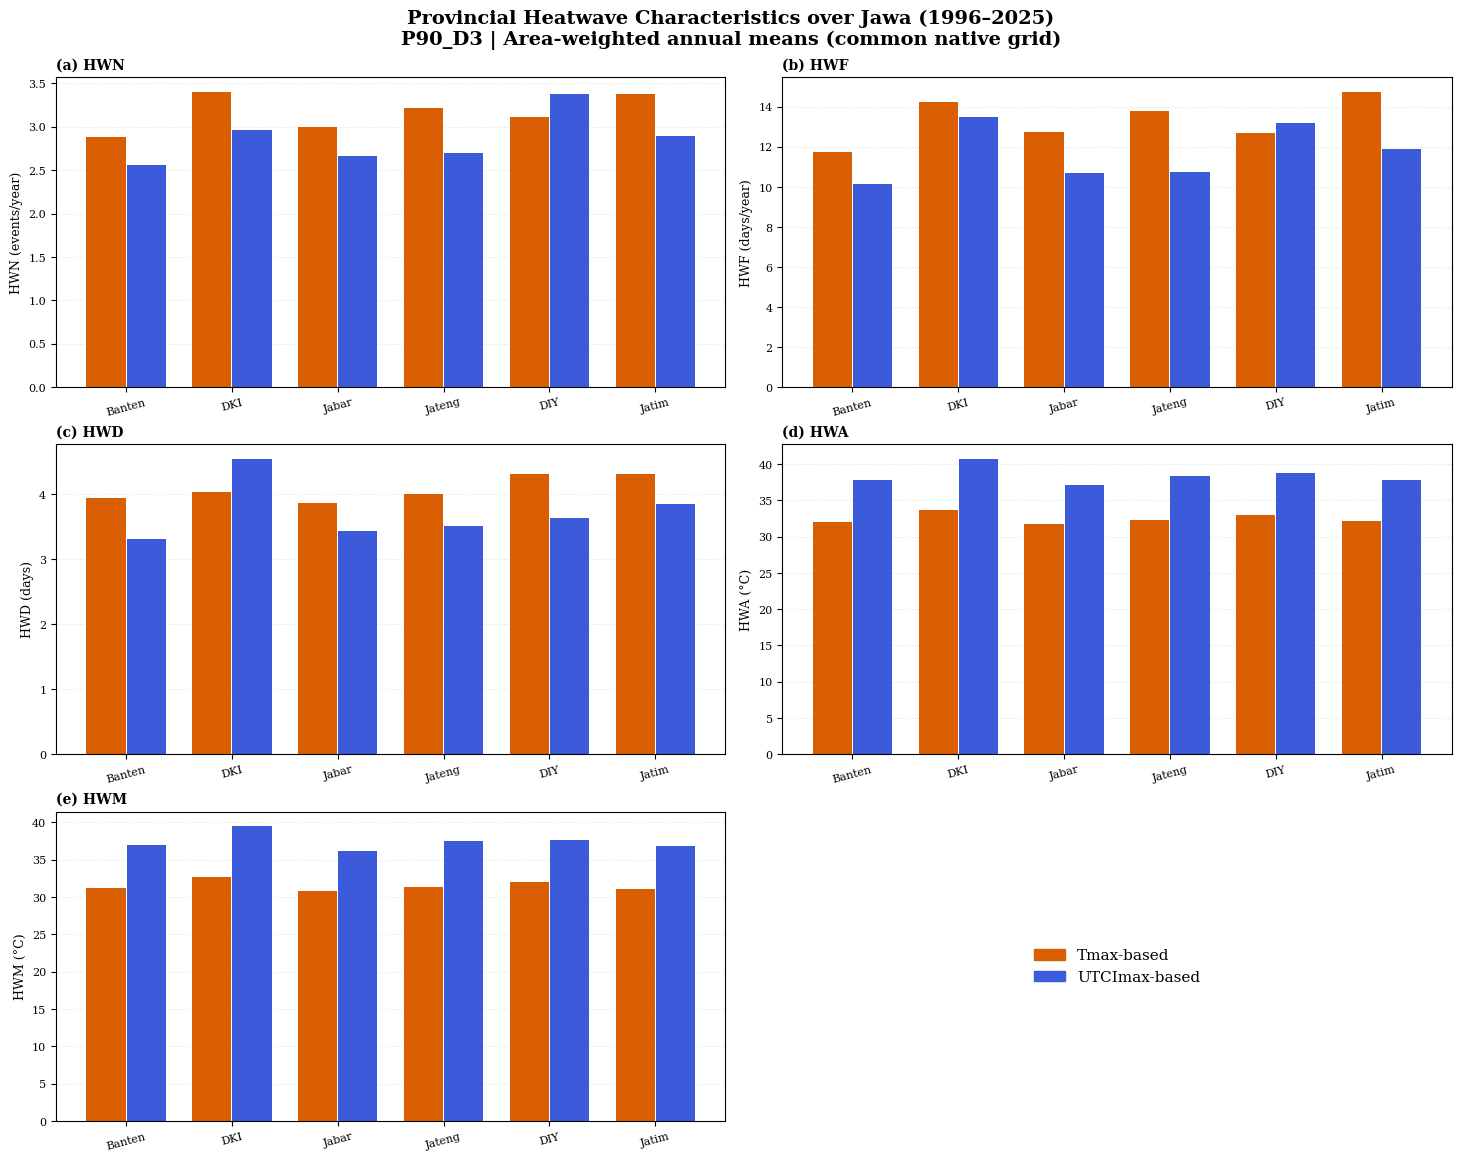

D:\Daps\Data\UTCI\Hasil_UTCI_Jawa_1996_2025\TMAX_UTCI_6_PROVINSI_JAWA_GABUNGAN_JOURNAL_SMOOTH\plots\FIG03_Provincial_Climatology_Five_Metrics_P90_D3.png


In [14]:
from matplotlib.patches import Patch
fig, axs = plt.subplots(3, 2, figsize=(14.5, 11.5), constrained_layout=True)
for i, metric in enumerate(METRIC_CODES):
    ax=axs.flat[i]
    td=trend_df[trend_df.metric.eq(metric)].set_index(['province','basis'])
    xt=np.arange(len(province_order))
    tv=np.array([td.loc[(p,'Tmax'),'mean_1996_2025'] for p in province_order])
    uv=np.array([td.loc[(p,'UTCImax'),'mean_1996_2025'] for p in province_order])
    ax.bar(xt-.19,tv,width=.37,color=TMAX_COLOR,label='Tmax-based')
    ax.bar(xt+.19,uv,width=.37,color=UTCI_COLOR,label='UTCImax-based')
    ax.set_xticks(xt, [province_short[p] for p in province_order], rotation=15)
    ax.set_ylabel(f'{metric} ({METRIC_UNIT[metric]})')
    ax.set_title(f'({chr(97+i)}) {metric}',loc='left',fontweight='bold')
    ax.grid(axis='y',ls=':',alpha=.35)
    ax.set_axisbelow(True)
axs.flat[-1].axis('off')
axs.flat[-1].legend(handles=[Patch(color=TMAX_COLOR,label='Tmax-based'),Patch(color=UTCI_COLOR,label='UTCImax-based')],loc='center',frameon=False,fontsize=11)
fig.suptitle(f'Provincial Heatwave Characteristics over Jawa ({START_YEAR}–{END_YEAR})\n{MAIN_SCENARIO} | Area-weighted annual means (common native grid)', fontsize=14,weight='bold')
out=PLOT_DIR/f'FIG03_Provincial_Climatology_Five_Metrics_{MAIN_SCENARIO}.png'
fig.savefig(out,dpi=FIG_DPI,bbox_inches='tight')
if SAVE_PDF: fig.savefig(out.with_suffix('.pdf'), dpi=FIG_DPI,bbox_inches='tight')
plt.show();plt.close(fig)
print(out)

## Figures 4a–4e — Grafik enam provinsi untuk setiap indeks (1996–2025)
**Setiap indeks satu figure 3×2** agar keterbacaan tetap baik. Garis tipis = nilai tahunan; garis tebal = rerata bergerak 5 tahun; garis putus-putus = estimasi tren Theil–Sen. Label slope per dekade ditampilkan pada panel dengan p Kendall (tanpa menyamakan besar HWA/HWM Tmax dan UTCI sebagai suhu fisik identik).

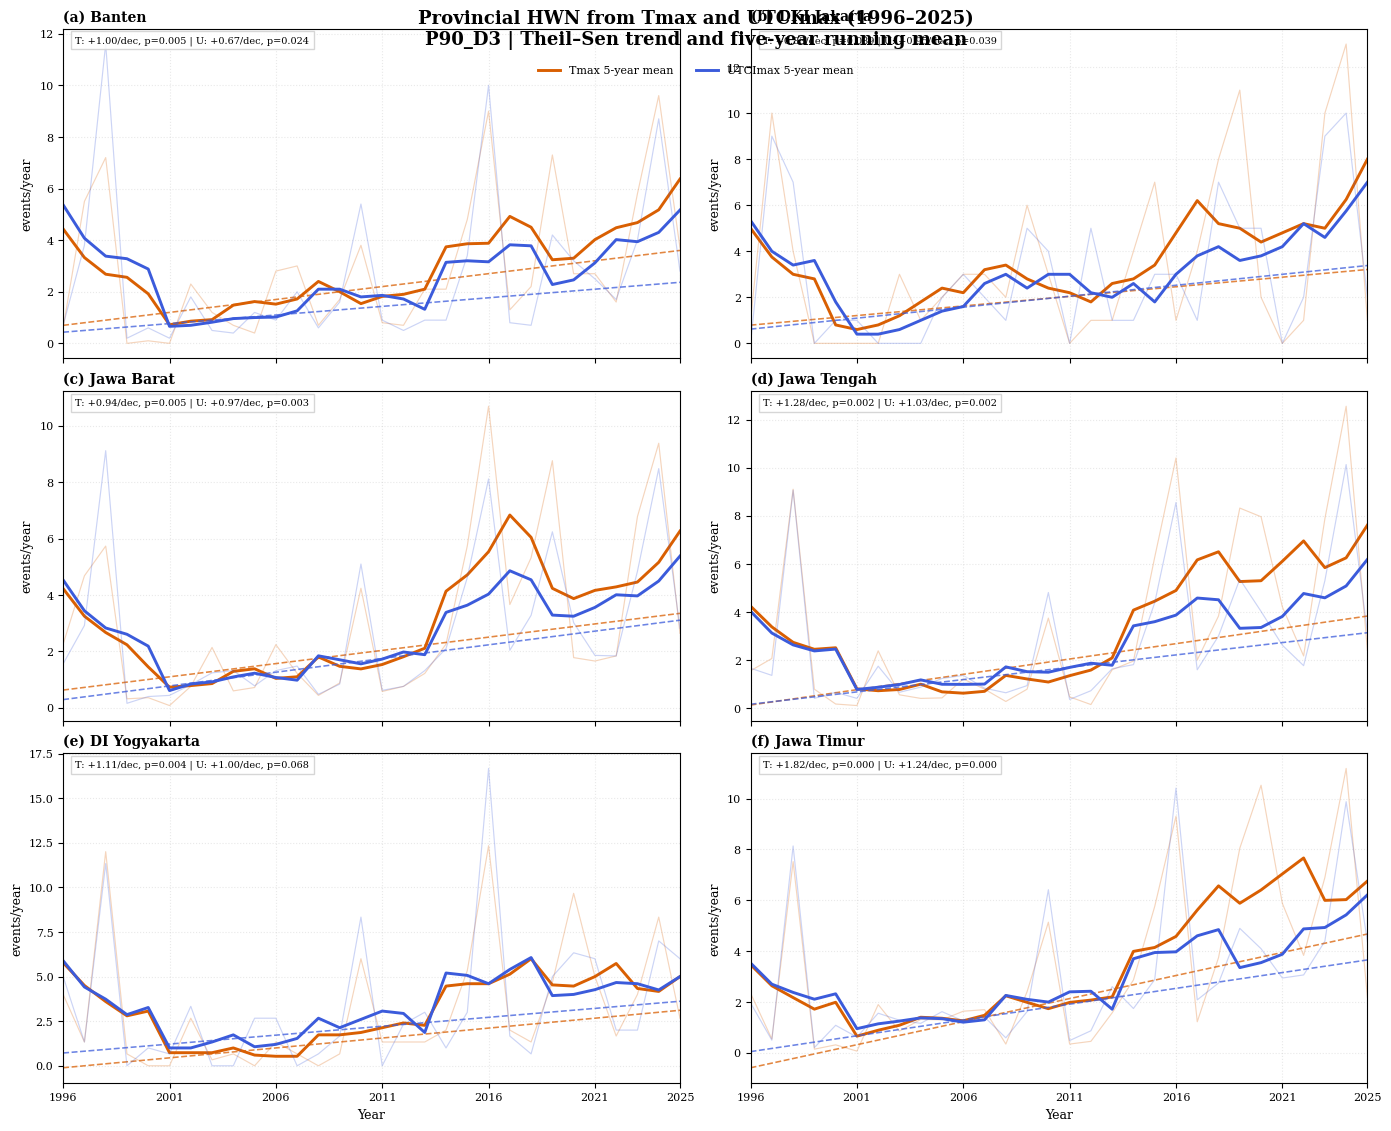

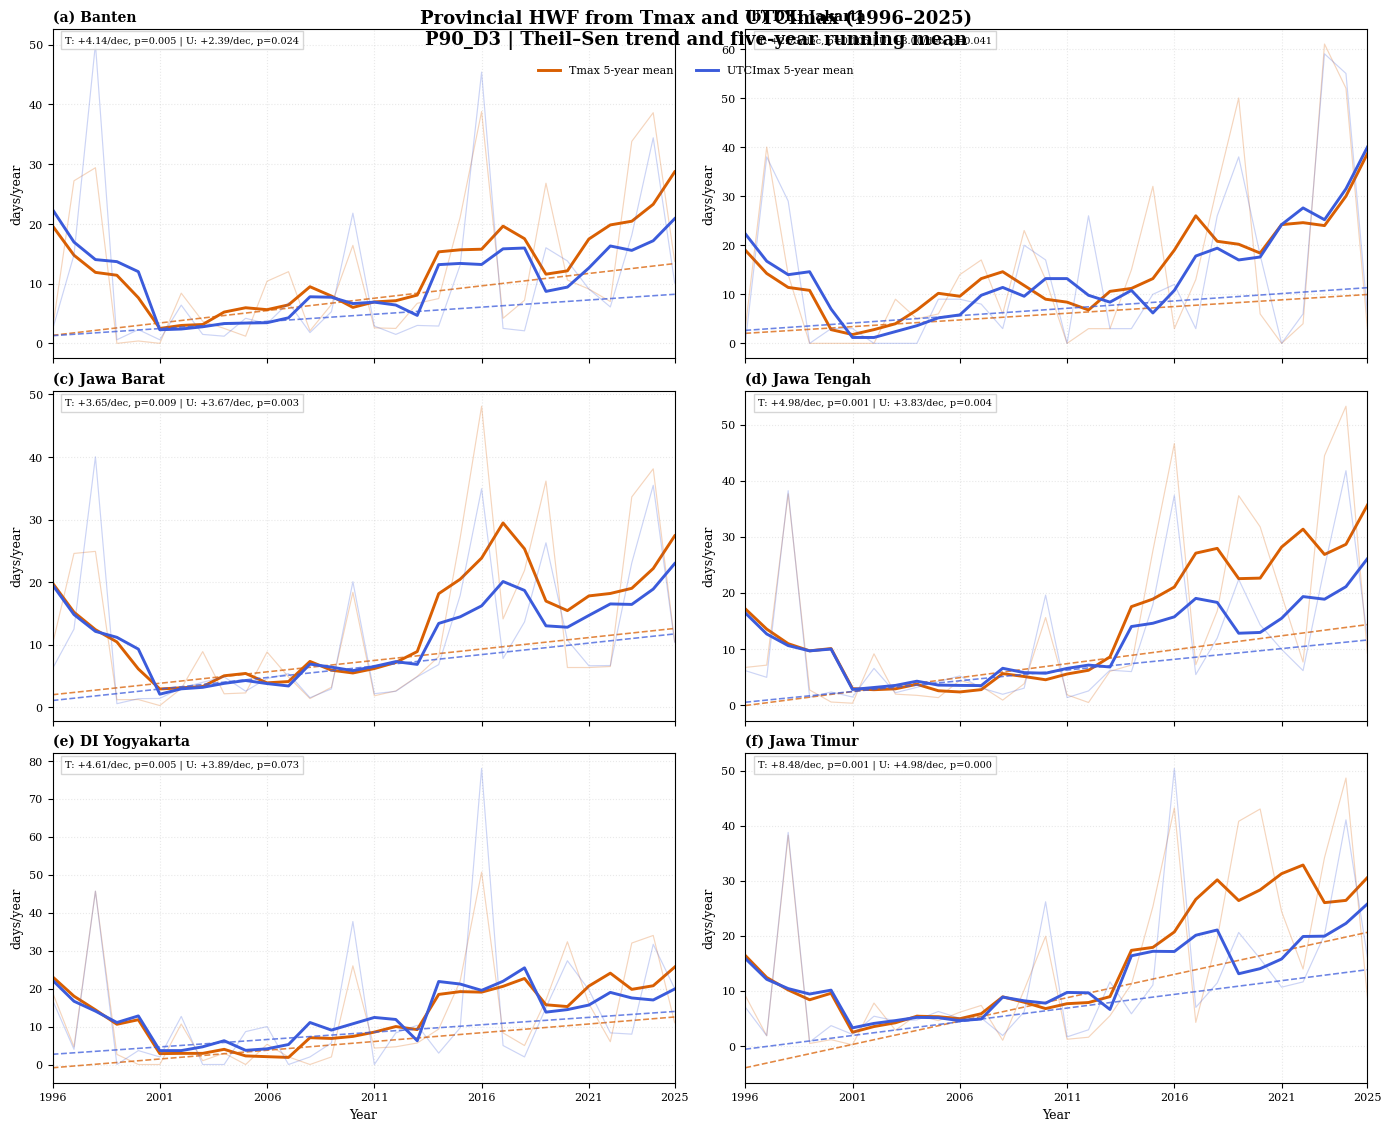

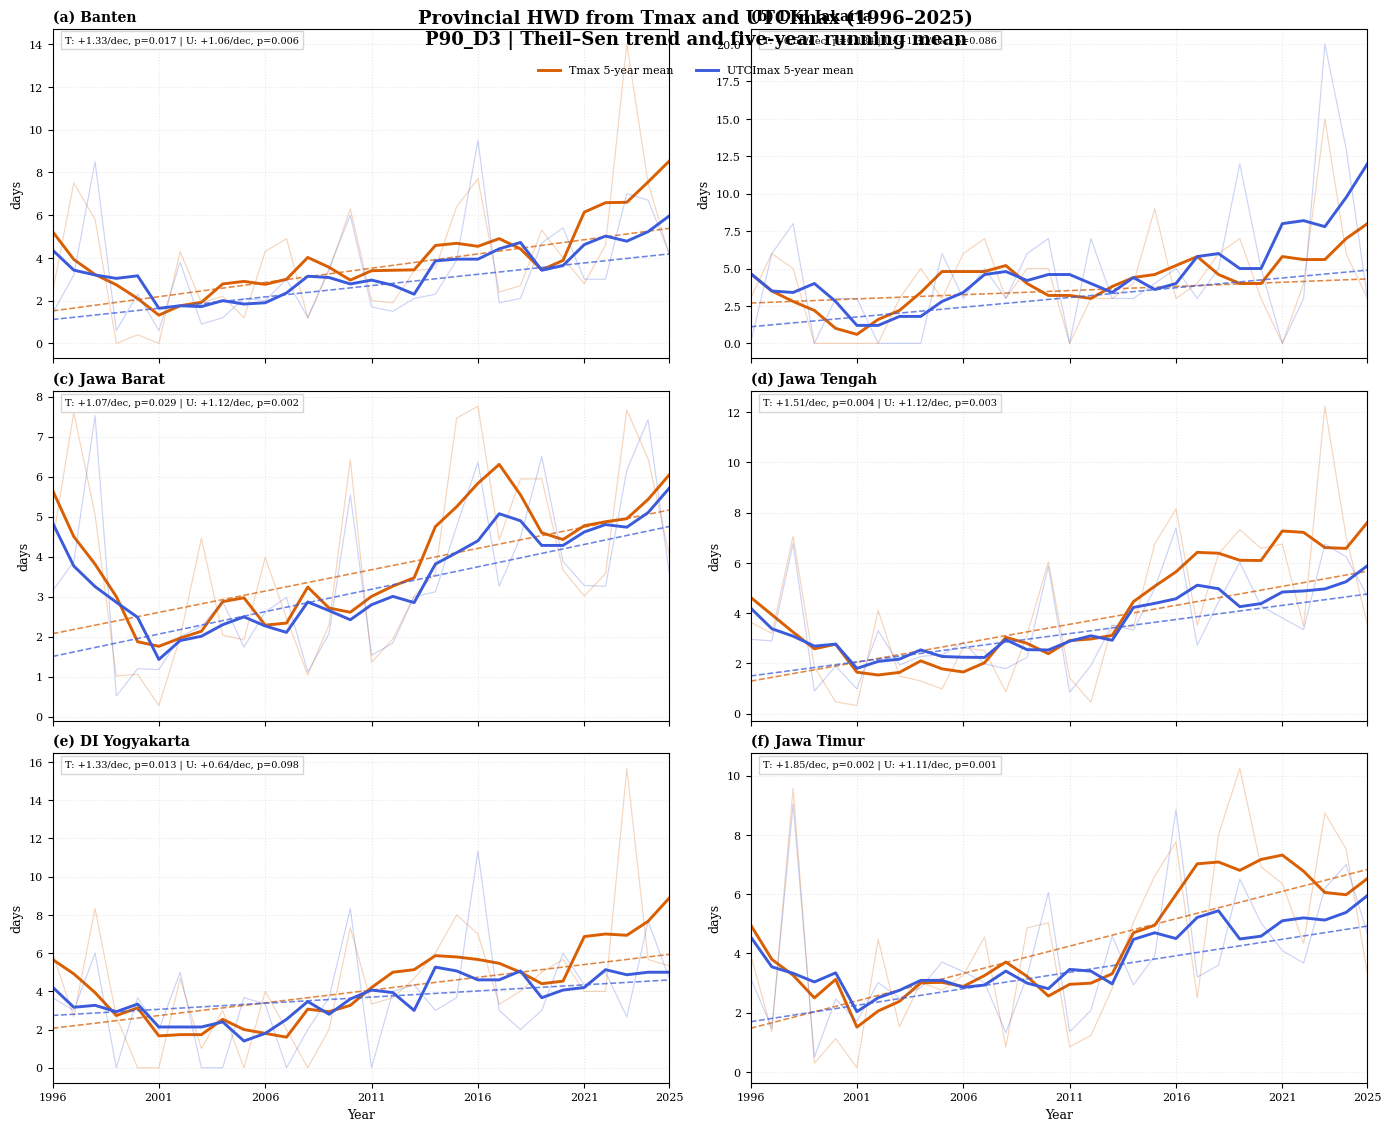

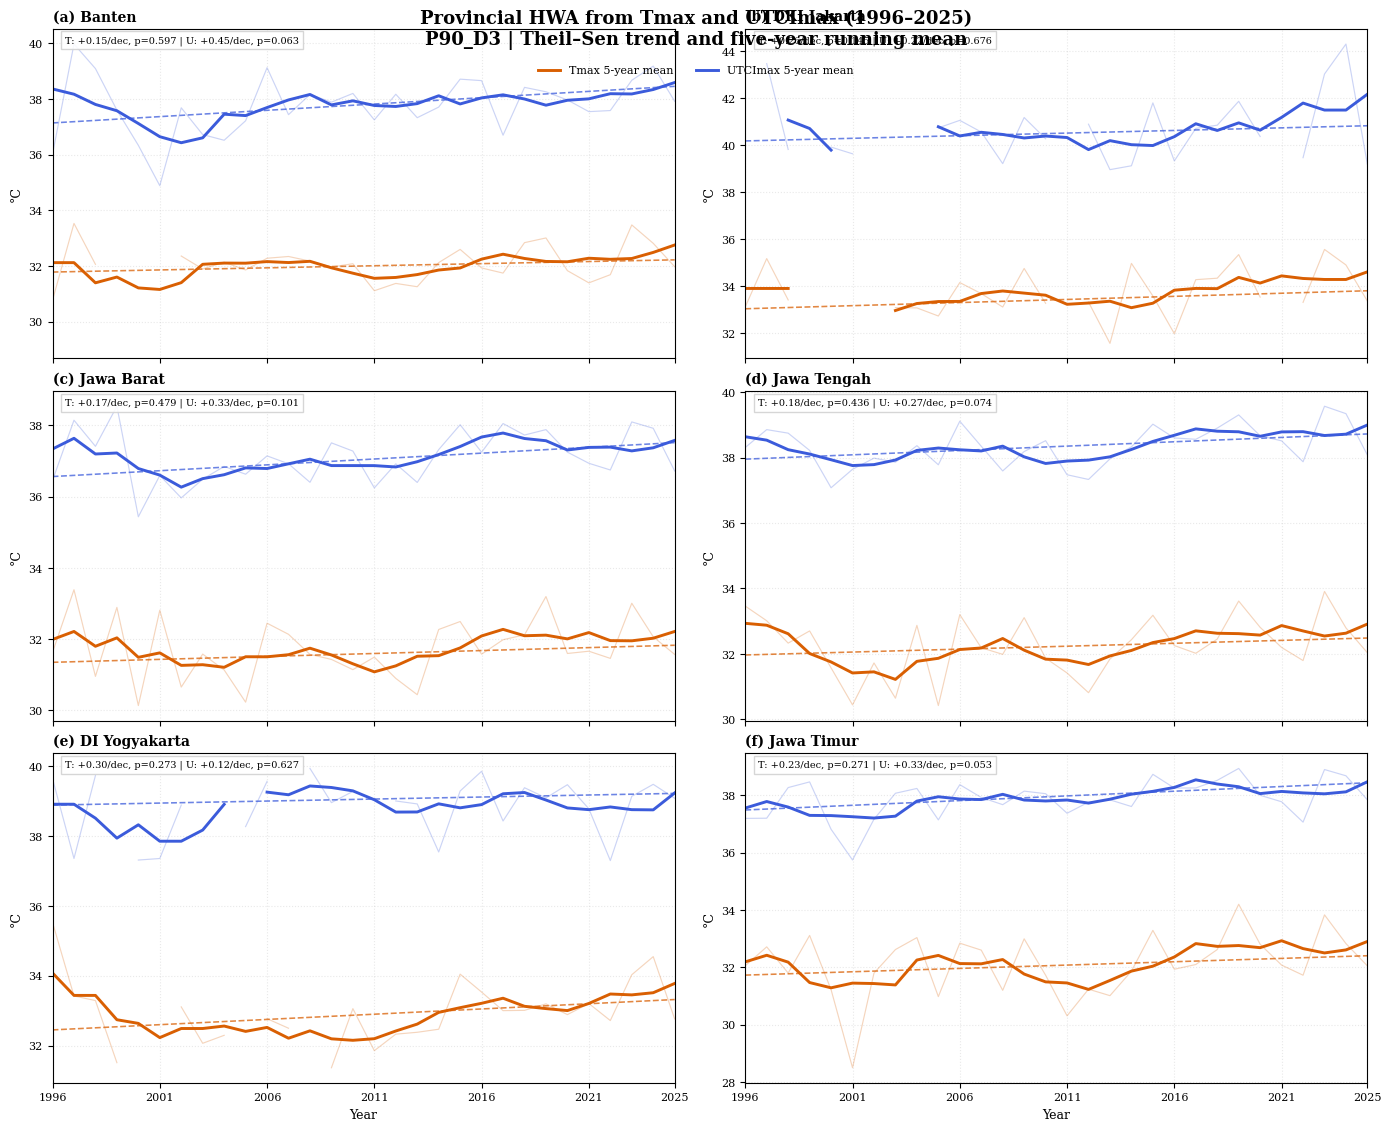

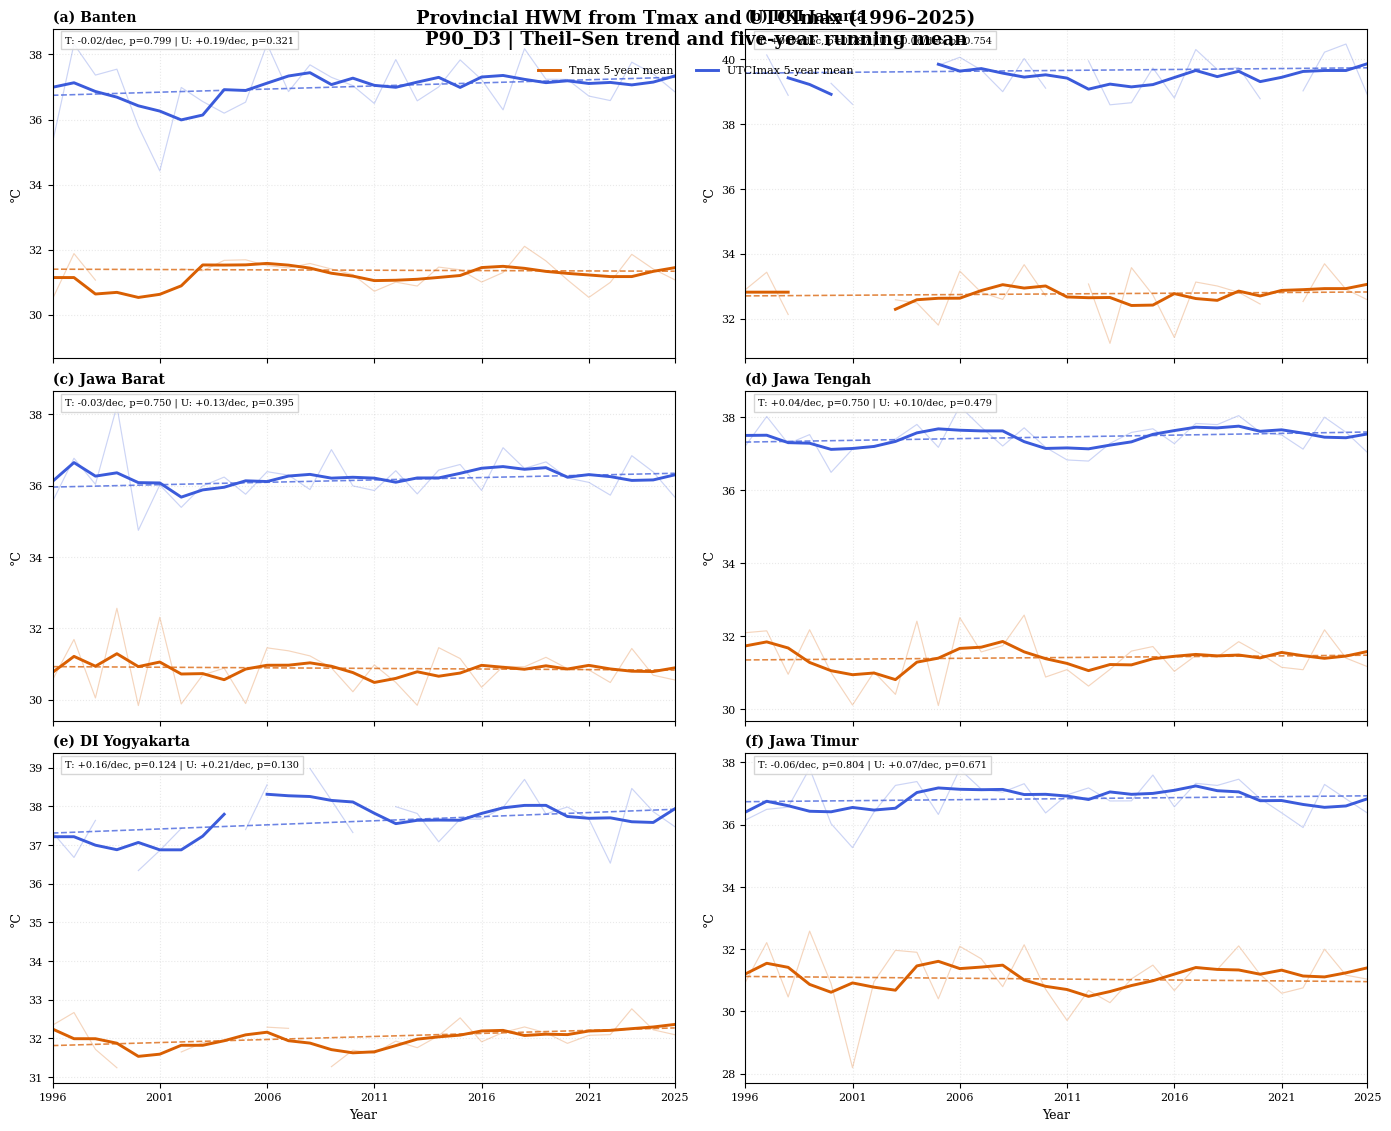

In [15]:
for metric in METRIC_CODES:
    fig, axs=plt.subplots(3,2,figsize=(13.8,11.2),sharex=True,constrained_layout=True)
    for j,prov in enumerate(province_order):
        ax=axs.flat[j]
        for basis,color in [('Tmax',TMAX_COLOR),('UTCImax',UTCI_COLOR)]:
            ss=prov_annual.query('province == @prov and basis == @basis and metric == @metric').sort_values('year')
            x=ss.year.to_numpy(dtype=float);y=ss.value.to_numpy(dtype=float)
            ax.plot(x,y,color=color,linewidth=.85,alpha=.26)
            ma=pd.Series(y).rolling(5,center=True,min_periods=3).mean().to_numpy()
            ax.plot(x,ma,color=color,linewidth=2.1,label=f'{basis} 5-year mean')
            good=np.isfinite(y)
            if good.sum()>=8 and np.nanstd(y[good])>0:
                ts=theilslopes(y[good],x[good])
                ax.plot(x,ts.intercept+ts.slope*x,ls='--',color=color,lw=1.15,alpha=.75)
        tt=trend_df[(trend_df.province==prov)&(trend_df.metric==metric)]
        infotext=' | '.join([f'{"T" if t.basis=="Tmax" else "U"}: {t.slope_decade:+.2f}/dec, p={t.kendall_p:.3f}'
                            for t in tt.itertuples() if np.isfinite(t.slope_decade)])
        ax.text(.02,.98,infotext,transform=ax.transAxes,ha='left',va='top',fontsize=7.0,
                bbox=dict(facecolor='white',edgecolor='0.82',alpha=.88,pad=3))
        ax.set_title(f'({chr(97+j)}) {prov}',loc='left',weight='bold',fontsize=10)
        ax.grid(ls=':',alpha=.28)
        ax.set_ylabel(METRIC_UNIT[metric])
        annotate_grid_coverage(ax,prov)
        ax.set_xlim(START_YEAR,END_YEAR)
        ax.set_xticks([1996,2001,2006,2011,2016,2021,2025])
    for ax in axs[-1]: ax.set_xlabel('Year')
    hh,ll=axs.flat[0].get_legend_handles_labels()
    fig.legend(hh,ll,loc='upper center',bbox_to_anchor=(.5,.955),ncol=2,frameon=False)
    fig.suptitle(f'Provincial {metric} from Tmax and UTCImax ({START_YEAR}–{END_YEAR})\n{MAIN_SCENARIO} | Theil–Sen trend and five-year running mean',fontsize=13,weight='bold',y=.996)
    op=PLOT_DIR/f'FIG04_{metric}_Six_Province_Timeseries_{MAIN_SCENARIO}.png'
    fig.savefig(op,dpi=FIG_DPI,bbox_inches='tight')
    if SAVE_PDF: fig.savefig(op.with_suffix('.pdf'), dpi=FIG_DPI,bbox_inches='tight')
    plt.show();plt.close(fig)

## Figure 5 — Matriks tren per provinsi
Masing-masing metrik dan basis disajikan dalam dua tabel visual **nilai slope per dekade**. Tanda * menunjukkan p Kendall < 0,05. Karena unit antarmetrik berbeda, **angka tren tidak dibandingkan langsung antarbaris**.

*Warna pada tiap kolom dinormalisasi berdasarkan rentang tren metrik tersebut untuk menghindari perbandingan besaran dari unit berbeda; angka di dalam sel adalah tren aktual dan tanda * berarti p < 0,05.*

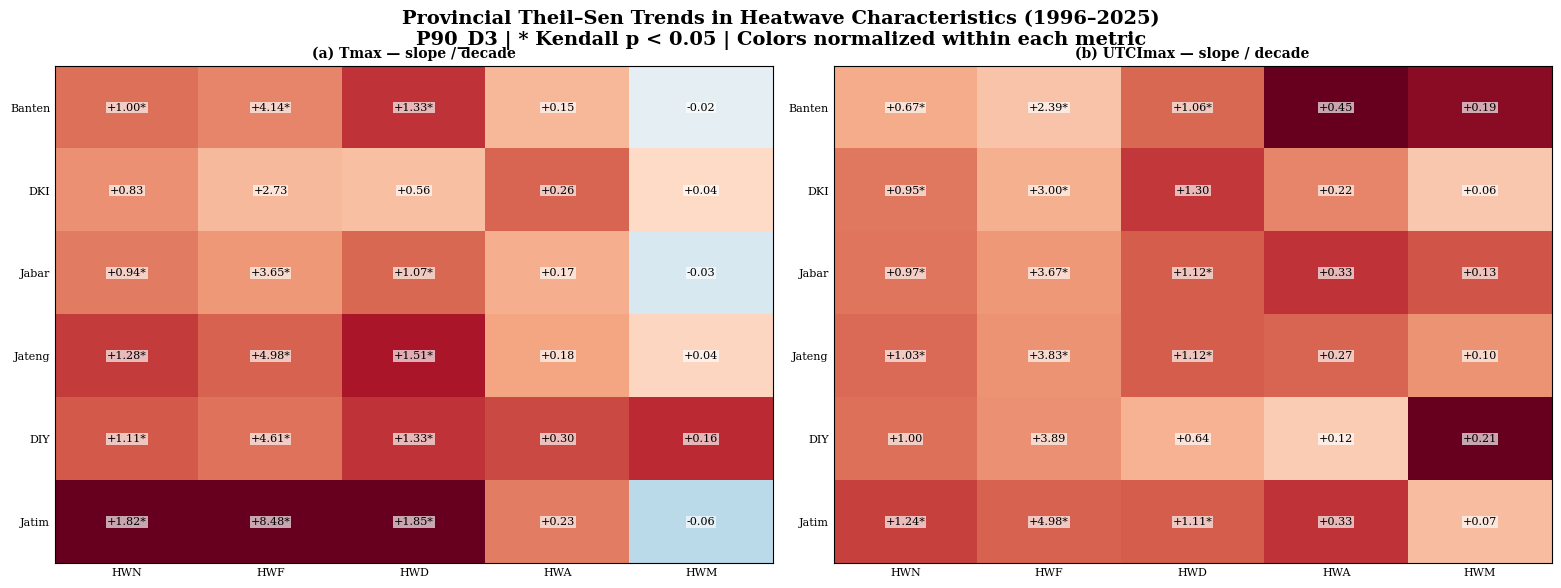

In [16]:
fig, axes=plt.subplots(1,2,figsize=(15.5,5.4),constrained_layout=True)
# Normalisasi per-metrik: hindari menyamakan skala tren HWF (hari) dengan HWA (°C).
metric_scale = {}
for metric in METRIC_CODES:
    data_m = trend_df.loc[trend_df.metric == metric, 'slope_decade'].to_numpy(dtype=float)
    metric_scale[metric] = max(1e-6, float(np.nanmax(np.abs(data_m)))) if np.isfinite(data_m).any() else 1.0
for ax,basis in zip(axes,['Tmax','UTCImax']):
    data=np.array([[trend_df.query('province == @prov and basis == @basis and metric == @metric').slope_decade.iloc[0]
                    for metric in METRIC_CODES] for prov in province_order])
    normalized = np.column_stack([data[:, k] / metric_scale[m] for k, m in enumerate(METRIC_CODES)])
    ax.imshow(np.ma.masked_invalid(normalized),cmap='RdBu_r',vmin=-1,vmax=1,aspect='auto')
    ax.set_xticks(np.arange(len(METRIC_CODES)),METRIC_CODES)
    ax.set_yticks(np.arange(len(province_order)),[province_short[p] for p in province_order])
    for ii,p in enumerate(province_order):
        for jj,m in enumerate(METRIC_CODES):
            row=trend_df.query('province == @p and basis == @basis and metric == @m').iloc[0]
            s=('NA' if not np.isfinite(row.slope_decade) else f'{row.slope_decade:+.2f}' + ('*' if row.significant_0_05 else ''))
            ax.text(jj,ii,s,ha='center',va='center',fontsize=8.1,color='black',bbox=dict(facecolor='white',alpha=.65,edgecolor='none',pad=.6))
    ax.set_title(f'({"a" if basis=="Tmax" else "b"}) {basis} — slope / decade',weight='bold')
    ax.tick_params(length=0)
fig.suptitle(f'Provincial Theil–Sen Trends in Heatwave Characteristics ({START_YEAR}–{END_YEAR})\n{MAIN_SCENARIO} | * Kendall p < 0.05 | Colors normalized within each metric',weight='bold',y=1.06)
op=PLOT_DIR/f'FIG05_Provincial_Trend_Matrix_{MAIN_SCENARIO}.png'
fig.savefig(op,dpi=FIG_DPI,bbox_inches='tight')
if SAVE_PDF:fig.savefig(op.with_suffix('.pdf'), dpi=FIG_DPI,bbox_inches='tight')
plt.show();plt.close(fig)

## Figures 6a–6e — Peta tiga panel smooth: Tmax / UTCImax / selisih
**Setiap metrik menghasilkan satu peta.** Panel (a) dan (b) memakai color scale sama; panel selisih (c) hanya untuk HWN, HWF, HWD. HWA/HWM ditampilkan sebagai dua panel tanpa pengurangan nilai karena UTCI adalah temperatur ekuivalen, bukan suhu udara. Interpolasi **linear hanya pada gambar**, tidak mengubah nilai per grid, tren atau perhitungan deteksi heatwave. Mask mengikuti footprint pusat-grid observasi dan gabungan enam batas provinsi (Natural Earth 10m). Peta smooth dapat memperlihatkan transisi antargrid; **bukan bukti detail resolusi lebih tinggi**.

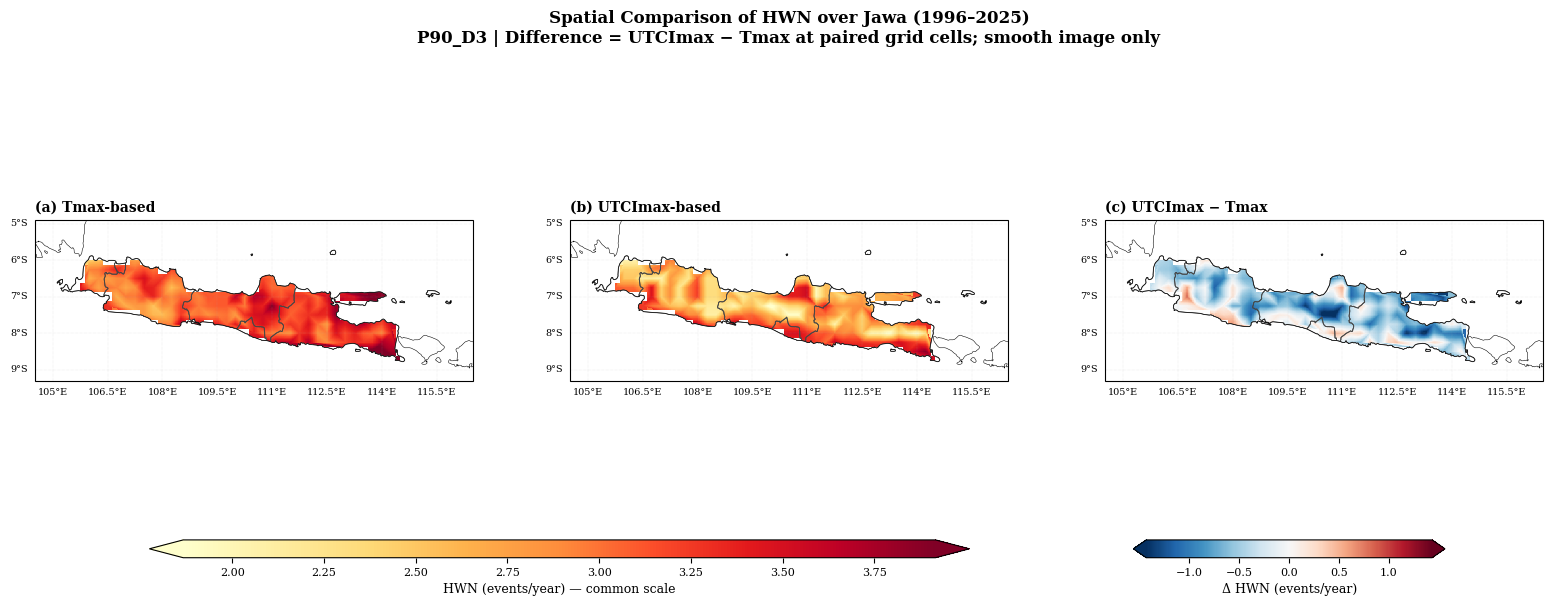

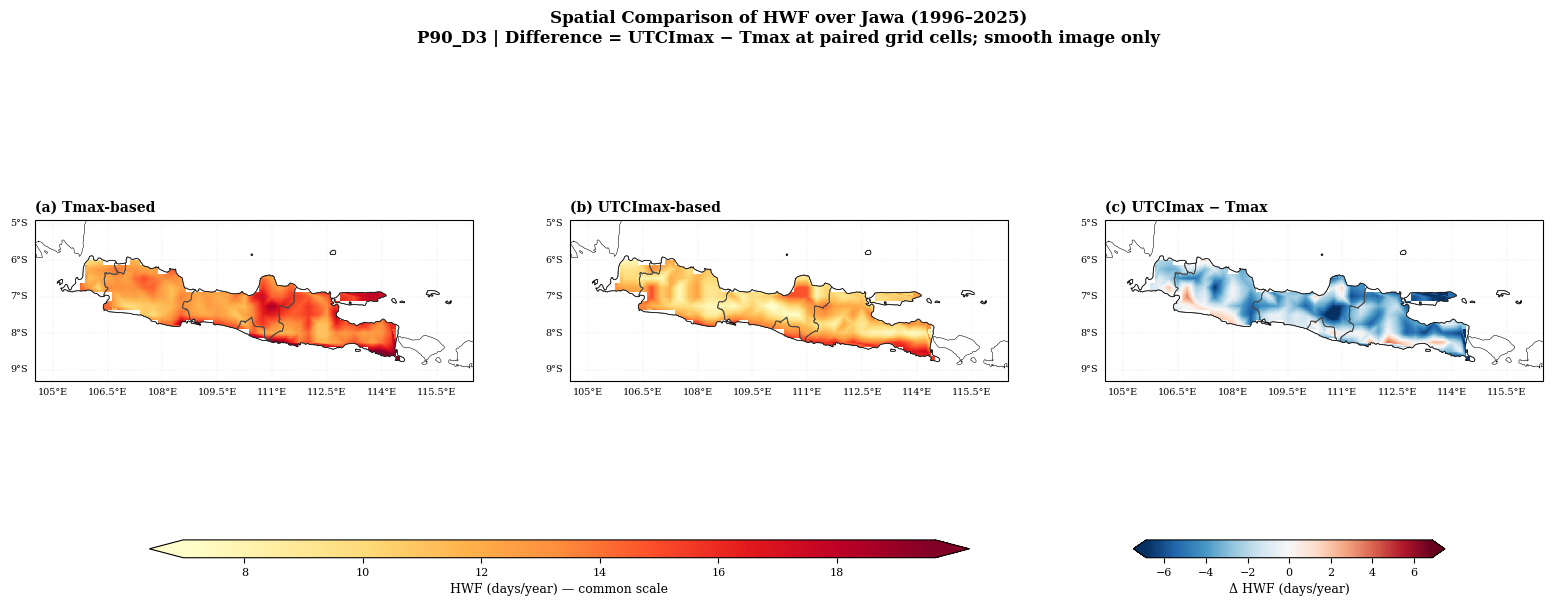

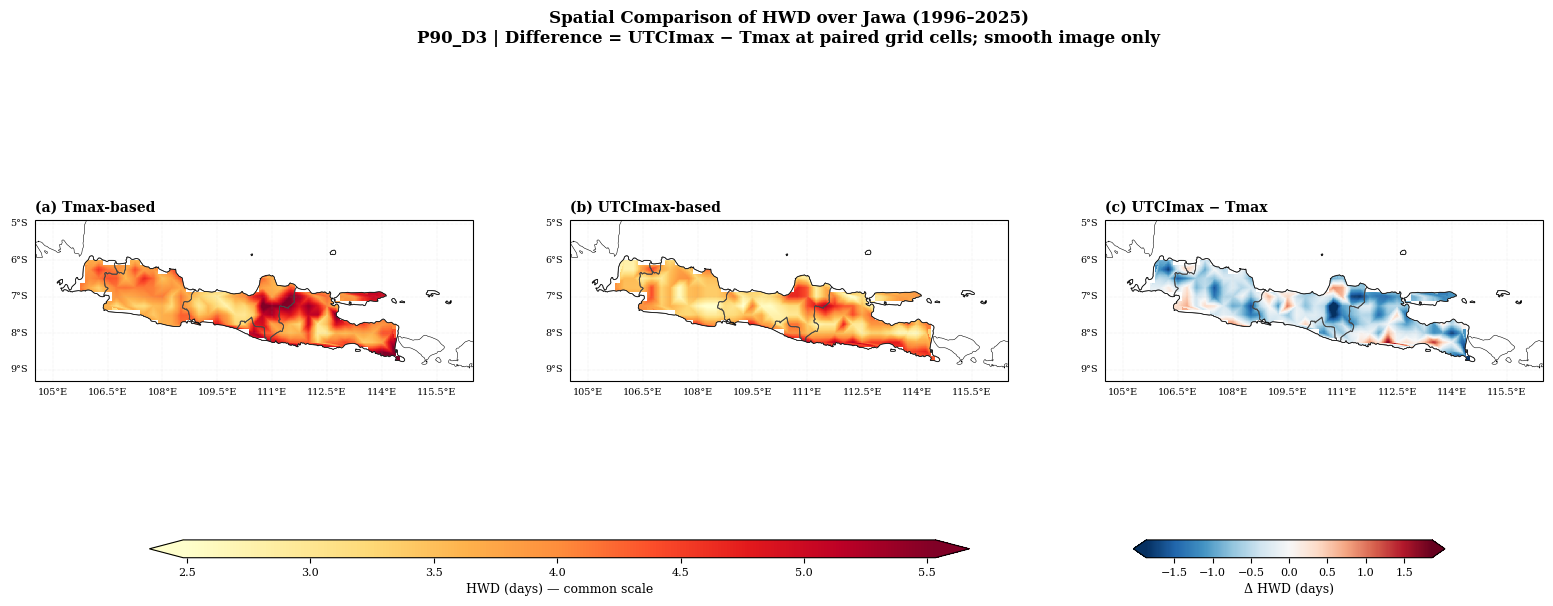

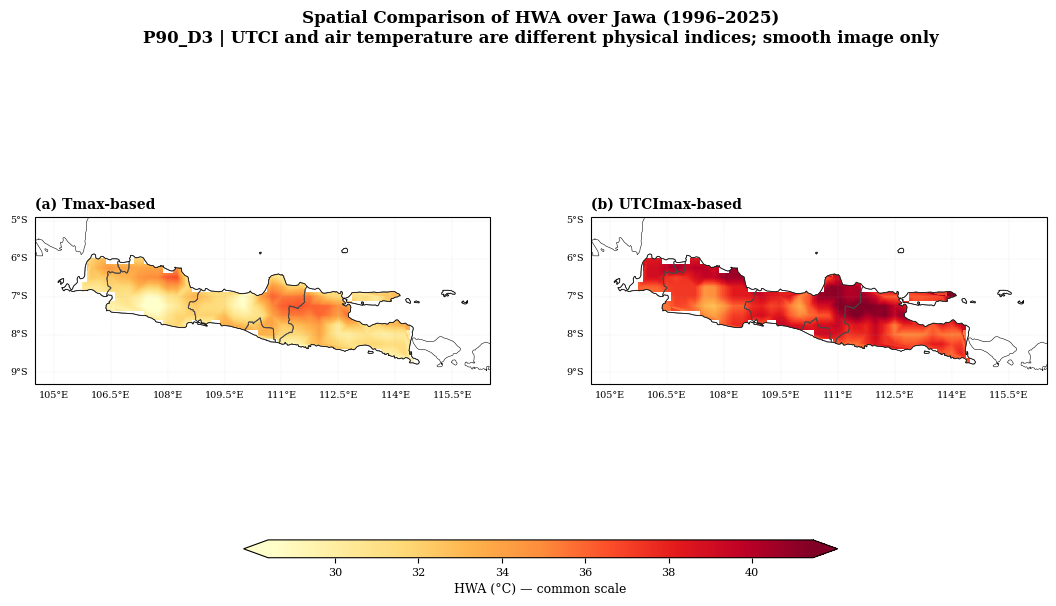

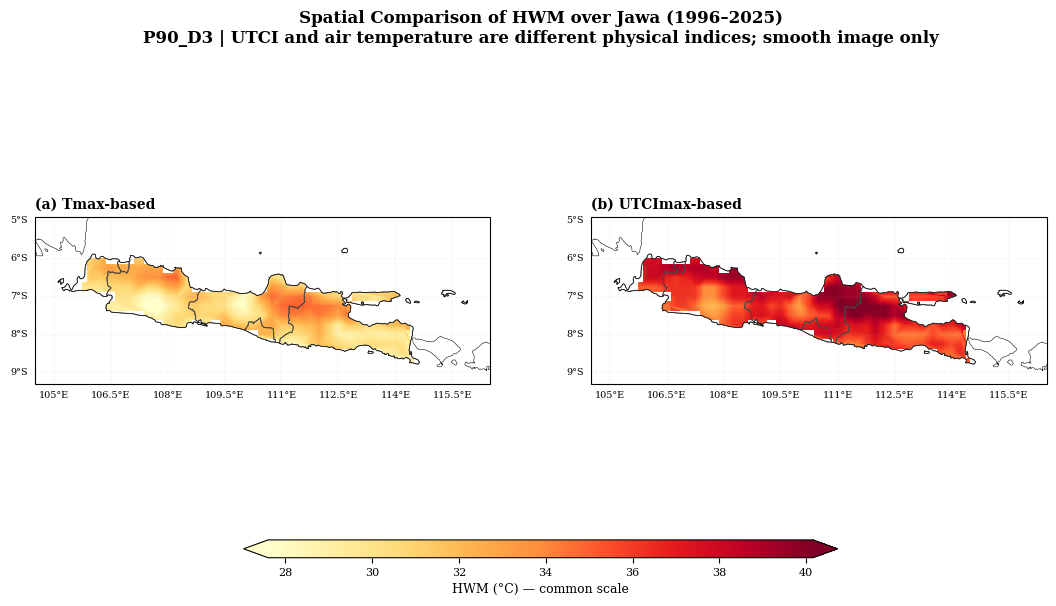

In [17]:
# Batas provinsi dan gabungan geometri. Hanya dari enam provinsi yang sudah dimuat di sel KDE.
all_province_geoms = {p:unary_union(province_geometries[p]) for p in province_order}
land_geometry=unary_union(list(all_province_geoms.values()))
try:
    from shapely import contains_xy as contains_xy_func
except ImportError:
    from shapely.vectorized import contains as contains_xy_func

_fine_cache=None
def fine_canvas():
    global _fine_cache
    if _fine_cache is None:
        gx=np.linspace(MAP_EXTENT[0],MAP_EXTENT[1],DISPLAY_NX)
        gy=np.linspace(MAP_EXTENT[2],MAP_EXTENT[3],DISPLAY_NY)
        xx,yy=np.meshgrid(gx,gy)
        # little edge buffer to preserve coastal boundary
        land=np.asarray(contains_xy_func(land_geometry.buffer(1e-8),xx,yy),dtype=bool)
        _fine_cache=(gx,gy,xx,yy,land)
    return _fine_cache

def smooth_field(field):
    """Interpolate continuous variable for image only; crop to native support and province polygons."""
    z=np.asarray(field,dtype=float).copy()
    z[~province_union_mask]=np.nan
    good=np.isfinite(z)
    if good.sum()<3: raise ValueError('Peta butuh >=3 grid valid. Ubah DISPLAY_RENDER ke native bila data terlalu jarang.')
    gx,gy,xx,yy,land=fine_canvas()
    lxx,lyy=np.meshgrid(cmp_lon,cmp_lat)
    points=np.column_stack((lxx[good],lyy[good]))

    try:
        out=griddata(points,z[good],(xx,yy),method='linear')
    except Exception as exc:
        print('Peringatan interpolasi linear gagal; fallback nearest:', type(exc).__name__)
        out=griddata(points,z[good],(xx,yy),method='nearest')
    holes=land & ~np.isfinite(out)
    if holes.any():
        nn=griddata(points,z[good],(xx,yy),method='nearest')
        out[holes]=nn[holes]
    # Native nearest-center footprint; cannot bridge missing grid cells or ocean.
    f=RegularGridInterpolator((cmp_lat,cmp_lon),good.astype(np.float32),method='nearest',bounds_error=False,fill_value=0.0)
    supported=f(np.column_stack([yy.ravel(),xx.ravel()])).reshape(xx.shape)>=.5
    out[~(land&supported)]=np.nan
    return gx,gy,out

def draw_metric(ax,z,cmap,vmin,vmax):
    z=np.asarray(z,dtype=float)
    cm=mpl.colormaps[cmap].copy();cm.set_bad((1,1,1,0))
    if DISPLAY_RENDER=='smooth':
        xx,yy,zz=smooth_field(z)
        image=ax.pcolormesh(xx,yy,np.ma.masked_invalid(zz),cmap=cm,vmin=vmin,vmax=vmax,shading='auto',transform=ccrs.PlateCarree(),rasterized=True,zorder=2)
    elif DISPLAY_RENDER=='native':
        zz=np.where(province_union_mask,z,np.nan)
        image=ax.pcolormesh(cmp_lon,cmp_lat,np.ma.masked_invalid(zz),cmap=cm,vmin=vmin,vmax=vmax,shading='nearest',transform=ccrs.PlateCarree(),rasterized=True,zorder=2)
    else: raise ValueError('DISPLAY_RENDER harus smooth / native')
    for geom in all_province_geoms.values():
        ax.add_geometries([geom],crs=ccrs.PlateCarree(),facecolor='none',edgecolor='0.28',lw=.65,zorder=4)
    ax.coastlines(resolution='10m',linewidth=.38,zorder=4)
    ax.set_extent(MAP_EXTENT,crs=ccrs.PlateCarree())
    gl=ax.gridlines(draw_labels=True,linestyle=':',linewidth=.35,alpha=.45)
    gl.top_labels=False;gl.right_labels=False
    gl.xlabel_style={'size':7};gl.ylabel_style={'size':7}
    return image

def cmap_limits(*arrs,difference=False):
    vec=np.concatenate([np.asarray(a)[np.isfinite(a)].ravel() for a in arrs if np.isfinite(a).any()])
    if vec.size==0: return (-1.,1.) if difference else (0.,1.)
    if difference:
        mx=np.percentile(np.abs(vec),98)
        return (-float(mx) if mx>0 else -1.,float(mx) if mx>0 else 1.)
    low=max(0.,float(np.percentile(vec,1))) if (vec>=0).all() else float(np.percentile(vec,1))
    high=float(np.percentile(vec,99))
    return (low,high if high>low else low+1.)

for metric in METRIC_CODES:
    tval=np.nanmean(annual_fields['Tmax'][metric],axis=0)
    uval=np.nanmean(annual_fields['UTCImax'][metric],axis=0)
    tval=np.where(province_union_mask,tval,np.nan)
    uval=np.where(province_union_mask,uval,np.nan)
    vmin,vmax=cmap_limits(tval,uval)
    # HWA/HWM adalah nilai indeks absolut dengan makna fisik berbeda.
    # Jangan hitung UTCI minus Tmax untuk kedua intensitas itu.
    has_diff = metric in ('HWN','HWF','HWD')
    ncols=3 if has_diff else 2
    fig,axs=plt.subplots(1,ncols,figsize=(16.4 if has_diff else 11.0,6.6),
                         subplot_kw={'projection':ccrs.PlateCarree()})
    im1=draw_metric(axs[0],tval,'YlOrRd',vmin,vmax)
    draw_metric(axs[1],uval,'YlOrRd',vmin,vmax)
    labels=['Tmax-based','UTCImax-based']
    if has_diff:
        diff=np.where(np.isfinite(tval)&np.isfinite(uval),uval-tval,np.nan)
        dm,dx=cmap_limits(diff,difference=True)
        im3=draw_metric(axs[2],diff,'RdBu_r',dm,dx)
        labels.append('UTCImax − Tmax')
    for i,(ax,cap) in enumerate(zip(axs,labels)):
        ax.set_title(f'({chr(97+i)}) {cap}',loc='left',weight='bold',fontsize=10)
    fig.subplots_adjust(left=.04,right=.96,bottom=.22,top=.82,wspace=.22)
    if has_diff:
        c1=fig.add_axes([.11,.13,.50,.027])
        c2=fig.add_axes([.71,.13,.19,.027])
        cb=fig.colorbar(im3,cax=c2,orientation='horizontal',extend='both',extendfrac=0.045,extendrect=False)
        cb.set_label(f'Δ {metric} ({METRIC_UNIT[metric]})',fontsize=9)
    else:
        c1=fig.add_axes([.23,.13,.54,.027])
    cb=fig.colorbar(im1,cax=c1,orientation='horizontal',extend='both',extendfrac=0.045,extendrect=False)
    cb.set_label(f'{metric} ({METRIC_UNIT[metric]}) — common scale',fontsize=9)
    detail=('UTCI and air temperature are different physical indices'
            if not has_diff else 'Difference = UTCImax − Tmax at paired grid cells')
    fig.suptitle(f'Spatial Comparison of {metric} over Jawa ({START_YEAR}–{END_YEAR})\n'
                 f'{MAIN_SCENARIO} | {detail}; {DISPLAY_RENDER} image only',fontsize=12,weight='bold',y=.96)
    op=PLOT_DIR/f'FIG06_{metric}_Spatial_Tmax_UTCI_Comparison_{DISPLAY_RENDER}_{MAIN_SCENARIO}.png'
    fig.savefig(op,dpi=FIG_DPI,bbox_inches='tight',facecolor='white')
    if SAVE_PDF:fig.savefig(op.with_suffix('.pdf'), dpi=FIG_DPI,bbox_inches='tight',facecolor='white')
    plt.show();plt.close(fig)


## 7. Deteksi harian untuk studi kasus & pola bulanan (seperti notebook CaseStudy)
Hanya menghitung event mask untuk keperluan grafik kasus dan sebaran bulan. **Deteksi diulang terpisah per tahun kalender**, persis pola pengolahan notebook Tmax/UTCI Combined. Berlaku mask masing-masing indeks pada grid asli; perhitungan kategori “both / only” menggunakan validitas data kedua indeks pada hari yang sama. **Binary event map tidak dihaluskan** karena interpolasi pada kelas ya/tidak akan menyesatkan.

In [18]:
# Implementasi run-length yang sama dengan notebook sumber: dua-pass, tahunan.
def event_mask_from_daily(exceed, minimum):
    exceed=np.asarray(exceed,dtype=bool)
    end_run=np.zeros(exceed.shape,dtype=np.int16)
    run=np.zeros(exceed.shape[1:],dtype=np.int16)
    for t in range(len(exceed)):
        run=np.where(exceed[t],run+1,0).astype(np.int16)
        end_run[t]=run
    out=np.zeros(exceed.shape,dtype=bool)
    run=np.zeros(exceed.shape[1:],dtype=np.int16)
    for t in range(len(exceed)-1,-1,-1):
        run=np.where(exceed[t],run+1,0).astype(np.int16)
        out[t]=exceed[t]&((end_run[t]+run-1)>=minimum)
    return out

all_years=all_dates.year.to_numpy()
tmax_hw=np.zeros(tmax_values_cmp.shape,dtype=bool)
utci_hw=np.zeros(utci_values_cmp.shape,dtype=bool)
for year in YEARS:
    select=np.where(all_years==year)[0]
    vt=np.asarray(tmax_values_cmp[select],dtype=np.float32)
    vu=np.asarray(utci_values_cmp[select],dtype=np.float32)
    rt=tmax_thr_daily[select];ru=utci_thr_daily[select]
    tmax_hw[select]=event_mask_from_daily(np.isfinite(vt)&np.isfinite(rt)&(vt>rt),MIN_DURATION)
    utci_hw[select]=event_mask_from_daily(np.isfinite(vu)&np.isfinite(ru)&(vu>ru),MIN_DURATION)

# Tak perlu konstruksi common_valid_3d agar tidak menggandakan memori; province mask sudah common-grid.
mask_shared=(np.isfinite(tmax_values_cmp)&np.isfinite(utci_values_cmp)&
             np.isfinite(tmax_thr_daily)&np.isfinite(utci_thr_daily))

def province_area_pct(mask3d,prov_mask):
    w=np.where(prov_mask,weights2d,0.)
    denom=np.sum(w)
    if denom<=0: return np.full(mask3d.shape[0],np.nan)
    return 100*np.einsum('tij,ij->t',mask3d.astype(float),w,optimize=True)/denom

# Time series per province for each category, with fully common valid daily support for agreement.
prov_daily={}
for prov in province_order:
    mask=province_masks[prov]
    available=mask_shared & mask[None,:,:]
    t=tmax_hw & available
    u=utci_hw & available
    prov_daily[prov]={
        'Tmax':province_area_pct(t,mask), 'UTCImax':province_area_pct(u,mask),
        'Both':province_area_pct(t&u,mask),
        'Tmax_only':province_area_pct(t&~u,mask),
        'UTCI_only':province_area_pct(u&~t,mask),
        'coverage':province_area_pct(available,mask)
    }

# Auto case selection: province-pooled *coverage-weighted* overlap score in time.
combined_mask=province_union_mask
regional_t=province_area_pct(tmax_hw & mask_shared,combined_mask)
regional_u=province_area_pct(utci_hw & mask_shared,combined_mask)
regional_both=province_area_pct(tmax_hw & utci_hw & mask_shared,combined_mask)
if CASE_SELECTION=='overlap':
    score=2*regional_both + np.minimum(regional_t,regional_u)
elif CASE_SELECTION=='contrast': score=np.abs(regional_t-regional_u)
elif CASE_SELECTION=='tmax': score=regional_t
elif CASE_SELECTION=='utci': score=regional_u
else: raise ValueError('CASE_SELECTION harus overlap / contrast / tmax / utci')
score_smoothed=pd.Series(score,index=all_dates).rolling(CASE_SMOOTH_DAYS,center=True,min_periods=1).mean()
if AUTO_CASE and not np.any(np.isfinite(score_smoothed.values)):
    raise ValueError('Tidak ada skor episode harian finite; periksa mask grid.')
if AUTO_CASE and np.nanmax(score_smoothed.values)==0:
    print('PERINGATAN: Tidak ada heatwave pada skenario ini; studi kasus menggunakan skor maksimum 0.')
center=score_smoothed.idxmax() if AUTO_CASE else pd.Timestamp(CASE_CENTER)
if center not in score_smoothed.index: raise ValueError('CASE_CENTER tidak ditemukan di time axis.')
idx_center=int(np.where(all_dates==center)[0][0])
start=max(0,idx_center-CASE_HALF_WINDOW_DAYS)
stop=min(len(all_dates),idx_center+CASE_HALF_WINDOW_DAYS+1)
case_days=all_dates[start:stop]
case_df=pd.DataFrame({'date':case_days})
for p in province_order:
    for stat,y in prov_daily[p].items():
        case_df[f'{province_short[p]}_{stat}_pct']=y[start:stop]
case_df.to_csv(TABLE_DIR/f'TABLE04_CaseStudy_Provincial_{center.strftime("%Y%m%d")}.csv',index=False)
print('Case-study selected:',center.date(), '| interval:',case_days[0].date(),case_days[-1].date())


Case-study selected: 2010-02-28 | interval: 2010-02-18 2010-03-10


## Figure 7 — Studi kasus tumpang tindih Tmax–UTCI per provinsi
**Enam panel per provinsi** untuk satu periode dipilih secara otomatis; satuan % dari seluruh grid daratan provinsi pada common grid (bukan % penduduk). Garis “both” menyatakan kejadian yang sama-sama teridentifikasi pada hari dan grid identik.

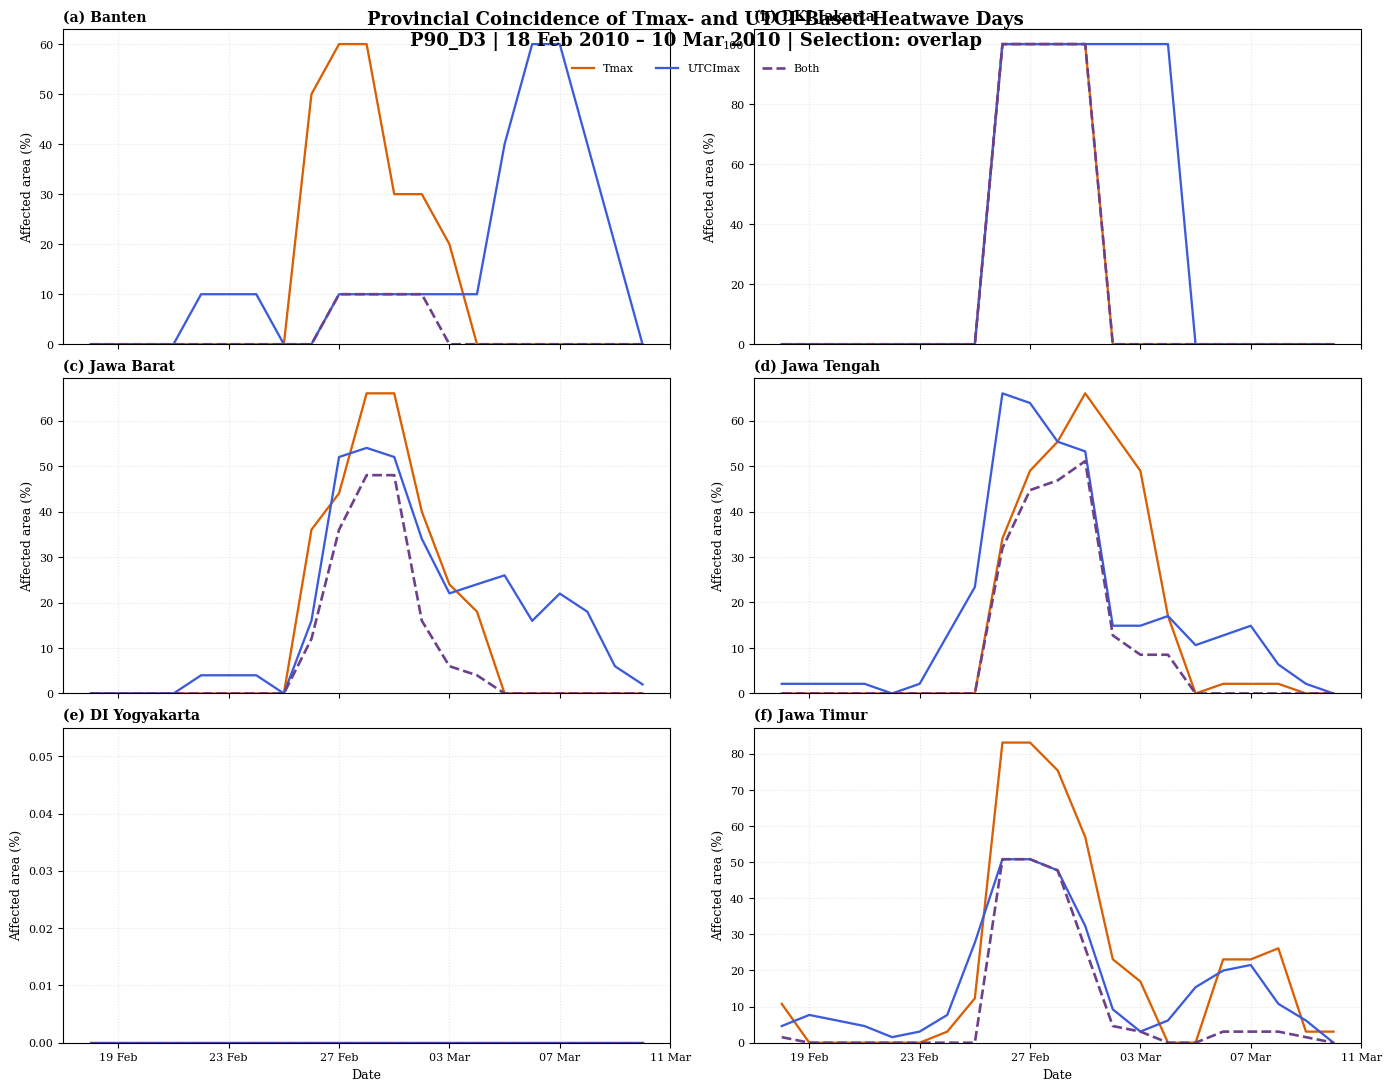

In [19]:
fig,axs=plt.subplots(3,2,figsize=(13.8,10.8),sharex=True,constrained_layout=True)
for i,p in enumerate(province_order):
    ax=axs.flat[i]
    for typ,col,sty,lw in [('Tmax',TMAX_COLOR,'-',1.65),('UTCImax',UTCI_COLOR,'-',1.65),('Both','#6c408b','--',1.9)]:
        ax.plot(case_days,prov_daily[p][typ][start:stop],color=col,ls=sty,lw=lw,label=typ)
    ax.set_title(f'({chr(97+i)}) {p}',loc='left',fontweight='bold')
    ax.set_ylabel('Affected area (%)')
    annotate_grid_coverage(ax,p)
    ax.set_ylim(bottom=0);ax.grid(ls=':',alpha=.3)
    ax.xaxis.set_major_locator(mdates.DayLocator(interval=4))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))
for ax in axs[-1]:ax.set_xlabel('Date')
h,l=axs.flat[0].get_legend_handles_labels()
fig.legend(h,l,loc='upper center',bbox_to_anchor=(.5,.955),ncol=3,frameon=False)
fig.suptitle(f'Provincial Coincidence of Tmax- and UTCI-Based Heatwave Days\n{MAIN_SCENARIO} | {case_days[0].strftime("%d %b %Y")} – {case_days[-1].strftime("%d %b %Y")} | Selection: {CASE_SELECTION}',weight='bold',y=.995,fontsize=13)
op=PLOT_DIR/f'FIG07_Case_Overlap_By_Province_{MAIN_SCENARIO}_{center.strftime("%Y%m%d")}.png'
fig.savefig(op,dpi=FIG_DPI,bbox_inches='tight')
if SAVE_PDF:fig.savefig(op.with_suffix('.pdf'), dpi=FIG_DPI,bbox_inches='tight')
plt.show();plt.close(fig)

## Figure 8 — Siklus bulanan HWF setiap provinsi
Jumlah grid-hari yang memenuhi kejadian dikelompokkan per bulan dan dirata-ratakan **per tahun** pada setiap grid dengan bobot `cos(latitude)`. **Heatwave yang melintasi batas bulan** dihitung menurut hari di bulan tersebut; analisis event tetap memakai persistensi harian minimum di tahun kalender.

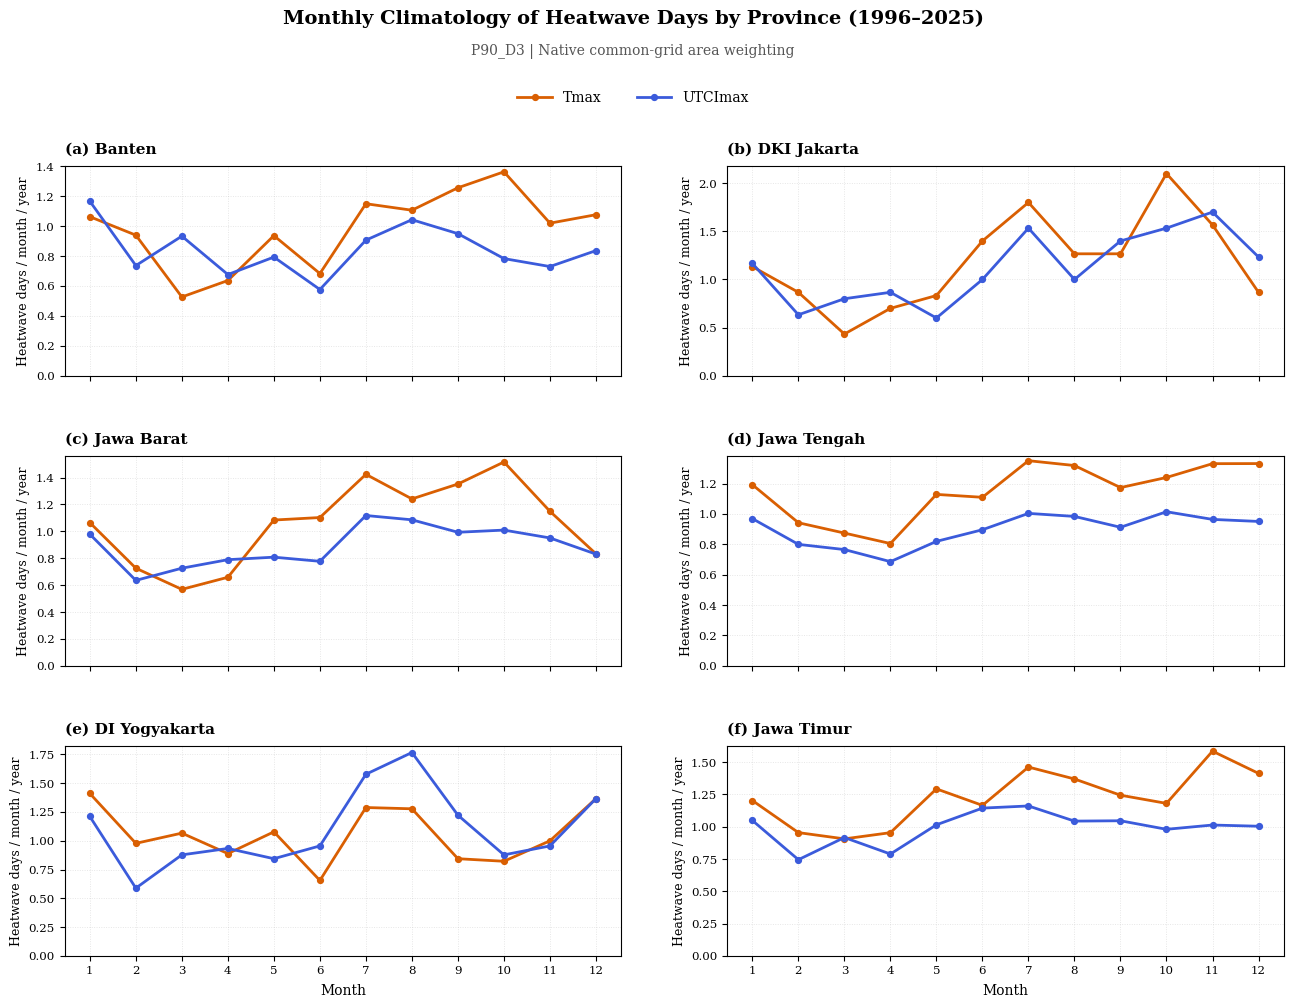

Figure tersimpan: D:\Daps\Data\UTCI\Hasil_UTCI_Jawa_1996_2025\TMAX_UTCI_6_PROVINSI_JAWA_GABUNGAN_JOURNAL_SMOOTH\plots\FIG08_Monthly_HWF_Six_Provinces_P90_D3.png


In [20]:

# ============================================================
# FIGURE 08 — MONTHLY CLIMATOLOGY OF HEATWAVE DAYS
# Tmax vs UTCImax | Six Provinces of Jawa | Journal Style
# ============================================================

monthly_rows = []

for prov in province_order:
    for basis, events in [('Tmax', tmax_hw), ('UTCImax', utci_hw)]:
        region = province_masks[prov]

        for month in range(1, 13):
            vals = []

            for year in YEARS:
                idx = (all_dates.year == year) & (all_dates.month == month)
                annual_month_days = np.sum(
                    events[idx], axis=0, dtype=float
                )[None]

                vals.append(
                    weighted_mean_grids(annual_month_days, region)[0]
                )

            monthly_rows.append({
                'province': prov,
                'basis': basis,
                'month': month,
                'avg_monthly_hw_days_per_year': np.nanmean(vals)
            })

monthly_df = pd.DataFrame(monthly_rows)

monthly_df.to_csv(
    TABLE_DIR / f'TABLE05_Monthly_Provincial_HWF_{MAIN_SCENARIO}.csv',
    index=False
)

# ============================================================
# PENGATURAN FIGURE
# ============================================================

fig, axs = plt.subplots(
    3, 2,
    figsize=(13.7, 10.4),
    sharex=True
)

# Sediakan area khusus untuk judul, subtitle, dan legenda
fig.subplots_adjust(
    left=0.085,
    right=0.975,
    bottom=0.075,
    top=0.835,
    hspace=0.38,
    wspace=0.19
)

# ============================================================
# PLOT SETIAP PROVINSI
# ============================================================

for i, p in enumerate(province_order):
    ax = axs.flat[i]

    for basis, color in [
        ('Tmax', TMAX_COLOR),
        ('UTCImax', UTCI_COLOR)
    ]:
        sel = monthly_df[
            (monthly_df.province == p) &
            (monthly_df.basis == basis)
        ].sort_values('month')

        ax.plot(
            sel.month,
            sel.avg_monthly_hw_days_per_year,
            color=color,
            lw=2.0,
            marker='o',
            ms=4.2,
            label=basis,
            zorder=3
        )

    ax.set_title(
        f'({chr(97+i)}) {p}',
        loc='left',
        fontsize=11,
        fontweight='bold',
        pad=9
    )

    annotate_grid_coverage(ax,p)
    ax.set_ylim(bottom=0)
    ax.set_ylabel(
        'Heatwave days / month / year',
        fontsize=9
    )

    ax.set_xticks(range(1, 13))
    ax.tick_params(axis='both', labelsize=8.5)

    ax.grid(
        True,
        linestyle=':',
        linewidth=0.65,
        alpha=0.35,
        zorder=0
    )

    ax.spines['top'].set_linewidth(0.8)
    ax.spines['right'].set_linewidth(0.8)

# Label bulan pada baris terakhir
for ax in axs[-1]:
    ax.set_xlabel('Month', fontsize=10, labelpad=6)

# ============================================================
# JUDUL UTAMA — TERPISAH DARI PANEL
# ============================================================

fig.suptitle(
    'Monthly Climatology of Heatwave Days by Province '
    f'({START_YEAR}–{END_YEAR})',
    fontsize=14,
    fontweight='bold',
    y=0.985
)

# Subtitle
fig.text(
    0.5,
    0.945,
    f'{MAIN_SCENARIO} | Native common-grid area weighting',
    ha='center',
    va='center',
    fontsize=10,
    color='#555555'
)

# ============================================================
# LEGENDA GLOBAL — DI BAWAH SUBTITLE
# ============================================================

handles, labels = axs.flat[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc='upper center',
    bbox_to_anchor=(0.5, 0.919),
    ncol=2,
    frameon=False,
    fontsize=10,
    handlelength=2.5,
    columnspacing=2.5
)

# ============================================================
# SIMPAN FIGURE
# ============================================================

op = PLOT_DIR / (
    f'FIG08_Monthly_HWF_Six_Provinces_{MAIN_SCENARIO}.png'
)

fig.savefig(
    op,
    dpi=FIG_DPI,
    bbox_inches='tight',
    facecolor='white'
)

if SAVE_PDF:
    fig.savefig(
        op.with_suffix('.pdf'), dpi=FIG_DPI,
        bbox_inches='tight',
        facecolor='white'
    )

plt.show()
plt.close(fig)

print(f'Figure tersimpan: {op}')


## 8. Ringkasan otomatis untuk Bab III skripsi — setelah Run All
Buat teks **berdasarkan hasil yang benar-benar terhitung**, bukan mengarang angka. `p < 0,05` dibaca sebagai signifikan untuk pengujian Kendall tanpa koreksi autokorelasi. Klaim tentang perbedaan Tmax dan UTCI tidak berarti beda risiko kesehatan secara langsung.

In [21]:
lines = [
    f'RINGKASAN HASIL PROVINSI Jawa {START_YEAR}–{END_YEAR}, DEFINISI {MAIN_SCENARIO}',
    'Data: native ERA5 Tmax dan ERA5-HEAT UTCImax pada pusat grid bersama; wilayah administratif Natural Earth 10m.',
    'Metode: indeks heatwave tahunan dari cache sumber; rerata cos(latitude); Theil–Sen/Kendall.',
    'Interpretasi: HWA/HWM adalah indeks nilai absolut selama hari kejadian; UTCI adalah temperatur ekuivalen.',
    ''
]
for metric in METRIC_CODES:
    lines.append(f'[{metric}]')
    for p in province_order:
        zt=trend_df.query('province == @p and basis == "Tmax" and metric == @metric').iloc[0]
        zu=trend_df.query('province == @p and basis == "UTCImax" and metric == @metric').iloc[0]
        cr=corr_df.query('province == @p and metric == @metric').iloc[0]
        def info(z):
            s=f'{z.mean_1996_2025:.2f} {METRIC_UNIT[metric]}'
            if np.isfinite(z.slope_decade):
                s+=f'; tren {z.slope_decade:+.2f} per dekade (Kendall p={z.kendall_p:.3g})'
            return s
        lines.append(f'- {p}: Tmax {info(zt)}; UTCImax {info(zu)}; r tahunan={cr.pearson_r:.2f}.')
    lines.append('')
lines += [
    'Catatan ilmiah: korelasi antartahun tidak membuktikan episode harian berimpit. Analisis overlap ada pada FIG07.',
    'Persentase area adalah fraksi grid berbobot luas, bukan persentase penduduk atau ukuran dampak kesehatan.',
    'Penggunaan interpolasi linear terbatas pada FIG06 sebagai visualisasi resolusi tinggi; semua nilai statistik asli.',
    'Untuk menyusun Bab III, sebutkan hanya angka, arah tren, dan p yang tercantum pada hasil sebenarnya.'
]
report='\n'.join(lines)
report_path=TABLE_DIR/f'Narasi_Dasar_Hasil_Per_Provinsi_{MAIN_SCENARIO}.txt'
report_path.write_text(report,encoding='utf-8')
print(report[:5500])
# Excel export opsional; CSV selalu tersedia.
try:
    with pd.ExcelWriter(TABLE_DIR/f'Provincial_Results_1996_2025_{MAIN_SCENARIO}.xlsx',engine='openpyxl') as xl:
        coverage_df.to_excel(xl,sheet_name='Data coverage',index=False)
        summary_df.to_excel(xl,sheet_name='KDE summary',index=False)
        prov_annual.to_excel(xl,sheet_name='Annual metrics',index=False)
        trend_df.to_excel(xl,sheet_name='Theil Sen Kendall',index=False)
        corr_df.to_excel(xl,sheet_name='Annual correlation',index=False)
        monthly_df.to_excel(xl,sheet_name='Monthly HWF',index=False)
    print('Workbook tersedia.')
except ImportError:
    print('openpyxl belum terinstal; tabel CSV sudah tetap tersimpan.')

RINGKASAN HASIL PROVINSI Jawa 1996–2025, DEFINISI P90_D3
Data: native ERA5 Tmax dan ERA5-HEAT UTCImax pada pusat grid bersama; wilayah administratif Natural Earth 10m.
Metode: indeks heatwave tahunan dari cache sumber; rerata cos(latitude); Theil–Sen/Kendall.
Interpretasi: HWA/HWM adalah indeks nilai absolut selama hari kejadian; UTCI adalah temperatur ekuivalen.

[HWN]
- Banten: Tmax 2.88 events/year; tren +1.00 per dekade (Kendall p=0.00538); UTCImax 2.56 events/year; tren +0.67 per dekade (Kendall p=0.0236); r tahunan=0.89.
- DKI Jakarta: Tmax 3.40 events/year; tren +0.83 per dekade (Kendall p=0.0888); UTCImax 2.97 events/year; tren +0.95 per dekade (Kendall p=0.0389); r tahunan=0.81.
- Jawa Barat: Tmax 2.99 events/year; tren +0.94 per dekade (Kendall p=0.0053); UTCImax 2.66 events/year; tren +0.97 per dekade (Kendall p=0.00327); r tahunan=0.91.
- Jawa Tengah: Tmax 3.22 events/year; tren +1.28 per dekade (Kendall p=0.00172); UTCImax 2.70 events/year; tren +1.03 per dekade (Kendall p

## 9. Pemeriksaan output dan keterbatasan
**Sebelum memasukkan gambar ke skripsi:**
1. Lihat angka valid grid/coverage setiap provinsi. Natural Earth Admin-1 punya keterbatasan garis batas; untuk pelaporan administratif resmi, pertimbangkan SHP Dukcapil yang sesuai dan verifikasi seluruh pusat grid.
2. Periksa kemiripan hasil annual metric gabungan dengan pipeline sumber dan peta hasil native vs smooth (`DISPLAY_RENDER='native'` untuk QC).
3. Ingat kernel KDE menunjukkan distribusi **seluruh hari**, sedangkan HWN/HWF/HWD/HWA/HWM dihitung hanya dari **episode ≥3 hari**. Jangan menyamakan “% hari di atas P90” dengan “% hari heatwave”.
4. Perbedaan HWF dan nilai UTCI bukan otomatis ukuran risiko kesehatan; penelitian ini membandingkan indikator atmosfer dan stres termal.
5. Hasil dan gambar akhir belum divalidasi terhadap file NetCDF asli pada komputer pengguna; cek semua gambar setelah menjalankan notebook.

In [22]:
files_png=sorted(PLOT_DIR.glob('FIG*.png'))
files_csv=sorted(TABLE_DIR.glob('TABLE*.csv'))
print(f'Figure PNG: {len(files_png)} (expected 17: 3 KDE + 1 bar + 5 timeseries + 1 trend + 5 maps + 1 case + 1 monthly)')
for f in files_png: print('  ',f.name)
print('\nTabel CSV:',len(files_csv))
for f in files_csv: print('  ',f.name)
print('\nOutput folder:',OUTPUT_DIR)
print('Selesai — hasil siap diperiksa sebelum dipakai dalam skripsi.')


Figure PNG: 17 (expected 17: 3 KDE + 1 bar + 5 timeseries + 1 trend + 5 maps + 1 case + 1 monthly)
   FIG01_Provincial_KDE_Absolute_Tmax_UTCImax_P90.png
   FIG02_Provincial_KDE_ThresholdRelative_Tmax_UTCImax_P90.png
   FIG02B_Provincial_KDE_ThresholdRelative_FixedY_Tmax_UTCImax_P90.png
   FIG03_Provincial_Climatology_Five_Metrics_P90_D3.png
   FIG04_HWA_Six_Province_Timeseries_P90_D3.png
   FIG04_HWD_Six_Province_Timeseries_P90_D3.png
   FIG04_HWF_Six_Province_Timeseries_P90_D3.png
   FIG04_HWM_Six_Province_Timeseries_P90_D3.png
   FIG04_HWN_Six_Province_Timeseries_P90_D3.png
   FIG05_Provincial_Trend_Matrix_P90_D3.png
   FIG06_HWA_Spatial_Tmax_UTCI_Comparison_smooth_P90_D3.png
   FIG06_HWD_Spatial_Tmax_UTCI_Comparison_smooth_P90_D3.png
   FIG06_HWF_Spatial_Tmax_UTCI_Comparison_smooth_P90_D3.png
   FIG06_HWM_Spatial_Tmax_UTCI_Comparison_smooth_P90_D3.png
   FIG06_HWN_Spatial_Tmax_UTCI_Comparison_smooth_P90_D3.png
   FIG07_Case_Overlap_By_Province_P90_D3_20100228.png
   FIG08_Monthly_HW